---
title: Hidden Markov Model with Control (Part 3)
subtitle: Control a Roomba using Active Inference and RxInfer
author: Kobus Esterhuysen
date: '2024-05-22'
date-modified: last-modified
categories:
  - Bayesian Inference
  - Active Inference
  - RxInfer
  - Julia
image: HMMwithControl.png
format:
  html:
    toc: true
    toc-depth: 4
    toc-expand: true
    toc-title: TOC
    code-fold: false
---

In [ ]:
#| hide
# BASED ON
  # HMMwithControl3_PORT^v2.ipynb
  # HMMwithControl2_PORT^v2.ipynb
    
# DONE
# v1 starts ------------------------------------------------
# add a motion sensor
# expand s0 to have combinations of its position and occupancy
# clean for publication
# v3 starts ------------------------------------------------
# align with ActiveInference_Notebook_Standards.md

# TODO


# Hidden Markov Model with Control (Part 3)
## 1 BUSINESS UNDERSTANDING

This is the third part of an effort to add control to the *Hidden Markov Model* RxInfer example. Eventually this work will be used in a more elaborate scheduling project making use of active inference.

We are still tracking a Roomba as it moves throughout a 3-room apartment consisting of a bedroom, a living room, and a bathroom. In this part, the agent additionally infers whether the room the Roomba is in is *occupied* by a person. This prepares the next part, in which the Roomba will get a preference for unoccupied rooms, so that it cleans where it does not disturb anyone: a first use case for control.

The Roomba now has three sensors:

- a camera that recognizes the floor texture (hardwood in the bedroom, carpet in the living room, tiles in the bathroom),
- a light sensor that measures the light intensity (the living room has skylights and is usually bright, the bathroom has no windows and is usually dark, and the bedroom is in between), and
- a motion sensor that detects movement, the most direct evidence that a person is present.

In Part 2, the light sensor turned out to add little to locating the Roomba. We keep it for continuity, but the new sensor of interest is the motion sensor.

To keep the model simple, room and occupancy are combined into a single state factor with six values: each room, either empty or occupied. This way, the model can express directly that when the Roomba moves to another room, whether that room is occupied has nothing to do with the room it left.

In addition, we continue to wrap the functionality with the usual structure:

- `create_envir()`
    - `execute()`
    - `observe()`
    - `state()` (true state, for evaluation only)
- `create_agent()`
    - `act()` [not yet]
    - `future()` [not yet]
    - `compute()`
    - `slide()` [not yet]

In the `compute()` function, which takes care of inference, the agent infers at each time step which room the Roomba is in and whether that room is occupied. Since the focus of this part is on inferring occupancy, the agent is given the state transition matrix $\boldsymbol{B}^{[0]}$: it knows how the Roomba moves and how occupancy changes. It learns only its observation matrices, one per sensor: $\boldsymbol{A}^{[0]}$ (Texture), $\boldsymbol{A}^{[1]}$ (Light) and $\boldsymbol{A}^{[2]}$ (Motion). As in the previous parts, and as in the active inference literature, $\mathbf{A}$ holds the observation (likelihood) matrices and $\mathbf{B}$ the state transition matrices, swapped compared to the original RxInfer example, which follows the engineering convention of using $A$ for state transitions.

In [3]:
versioninfo() ## Julia version

Julia Version 1.12.7
Commit 6d172b025e4 (2026-08-15 08:05 UTC)
Build Info:
  Official https://julialang.org release
Platform Info:
  OS: Linux (x86_64-linux-gnu)
  CPU: 12 × Intel(R) Core(TM) i7-8700B CPU @ 3.20GHz
  WORD_SIZE: 64
  LLVM: libLLVM-18.1.7 (ORCJIT, skylake)
  GC: Built with stock GC
Threads: 1 default, 1 interactive, 1 GC (on 12 virtual cores)


In [4]:
import Pkg
Pkg.add(Pkg.PackageSpec(;name="RxInfer"))
Pkg.add(Pkg.PackageSpec(;name="Random"))
Pkg.add(Pkg.PackageSpec(;name="Plots"))
Pkg.add(Pkg.PackageSpec(;name="XLSX"))
Pkg.add(Pkg.PackageSpec(;name="DataFrames"))
Pkg.add(Pkg.PackageSpec(;name="BenchmarkTools"))
Pkg.add(Pkg.PackageSpec(;name="Distributions"))
Pkg.add(Pkg.PackageSpec(;name="OffsetArrays"))

using RxInfer, Random, BenchmarkTools, Distributions, Plots, XLSX, DataFrames, OffsetArrays

     Project No packages added to or removed from `~/.julia/environments/v1.12/Project.toml`
    Manifest No packages added to or removed from `~/.julia/environments/v1.12/Manifest.toml`
     Project No packages added to or removed from `~/.julia/environments/v1.12/Project.toml`
    Manifest No packages added to or removed from `~/.julia/environments/v1.12/Manifest.toml`
     Project No packages added to or removed from `~/.julia/environments/v1.12/Project.toml`
    Manifest No packages added to or removed from `~/.julia/environments/v1.12/Manifest.toml`
     Project No packages added to or removed from `~/.julia/environments/v1.12/Project.toml`
    Manifest No packages added to or removed from `~/.julia/environments/v1.12/Manifest.toml`
     Project No packages added to or removed from `~/.julia/environments/v1.12/Project.toml`
    Manifest No packages added to or removed from `~/.julia/environments/v1.12/Manifest.toml`
     Project No packages added to or removed from `~/.julia/envir

In [5]:
Pkg.status()

Status `~/.julia/environments/v1.12/Project.toml`
  [6e4b80f9] BenchmarkTools v1.8.0
  [a93c6f00] DataFrames v1.8.2
  [31c24e10] Distributions v0.25.131
  [6fe1bfb0] OffsetArrays v1.17.0
  [91a5bcdd] Plots v1.41.7
  [86711068] RxInfer v5.5.2
  [fdbf4ff8] XLSX v0.13.1
  [9a3f8284] Random v1.11.0


In [6]:
## tuple0(x...): build a 0-based tuple (x^{[0]}, ..., x^{[N]}), mirroring the math.
##   - each argument becomes one entry: tuple0(v) wraps v; it never re-indexes v itself
##   - the index range 0:N is derived from the number of arguments
##   - entries may differ in shape, e.g. likelihood matrices for different modalities
## Returns an OffsetVector (mutable), not a Julia Tuple.
tuple0(x...) = OffsetVector(collect(x), 0:length(x)-1)

## offset0(v): re-index an existing vector from 0, e.g. a trajectory over t = 0, ..., T.
## Unlike tuple0, it does not wrap v; it shifts v's own indices.
offset0(v) = OffsetVector(v, 0:length(v)-1)

offset0 (generic function with 1 method)

**Why `tuple0()` rather than `OffsetVector()` directly?**

1. **It prevents a level mix-up.** With `OffsetVector`, it is easy to offset the *wrong level*:

```julia
    OffsetVector([1.0, 0.0, 0.0], 0:2)    ## the one-hot vector itself, re-indexed 0:2 (wrong level)
    OffsetVector([[1.0, 0.0, 0.0]], 0:0)  ## a tuple containing the one-hot vector (intended)
    tuple0([1.0, 0.0, 0.0])               ## the same as the second line, with no way to get it wrong
```

    The first line is valid code but means something else: the one-hot vector $\hat{\boldsymbol{s}}^{\ast[0,0]}$ itself, now indexed from 0, rather than the tuple $\hat{\mathbf{s}}^{\ast(0)} = \big(\hat{\boldsymbol{s}}^{\ast[0,0]}\big)$. Nothing would complain, and later code that indexes `[0]` would get a single number instead of a vector. `tuple0` always wraps its arguments as *entries*, so this mistake cannot happen.

2. **The index range is computed automatically.** With `OffsetVector`, the range is written by hand and has to agree with the number of entries: adding a second modality to `LAˣ` while forgetting to change `0:0` to `0:1` gives an error at best. `tuple0` derives the range from the number of arguments, so adding or removing an entry is a one-line change.

3. **It reads like the math.** `tuple0(A0, A1)` looks like $\big(\boldsymbol{A}^{[0]}, \boldsymbol{A}^{[1]}\big)$: entries separated by commas, nothing else. `OffsetVector([A0, A1], 0:1)` adds square brackets and a range that have nothing to do with the math.

4. **It states the intent.** `OffsetVector` says "an array with shifted indices", which could be anything. `tuple0` says "a tuple of factors or modalities, as in the math", the specific concept from (10.33). And since all tuples are built the same way, a search for `tuple0(` finds every one of them.

5. **There is one place to change things.** Changing how tuples work, e.g. switching to an immutable 0-based type, or adding a check that every column of every $\boldsymbol{A}$ and $\boldsymbol{B}$ sums to 1, means changing one line instead of every place a tuple is built.

6. **Entries of different shapes just work.** `collect` builds a vector of whatever is passed in, so `tuple0(A0, A1)` with a $3\times 3$ and a $2\times 3$ matrix gives a vector of matrices, which is exactly what a tuple of likelihood matrices with different numbers of observations needs.

## 2 DATA UNDERSTANDING

The data is simulated: the environment generates a time series of $T + 1 = 600$ ticks, $t = 0, \ldots, T$. At each tick, it records three kinds of one-hot encoded vectors:

- **Observations**, which the agent receives: the observation tuple $\hat{\mathbf{o}}^{(t)} = \big(\hat{\boldsymbol{o}}^{[t,0]}, \hat{\boldsymbol{o}}^{[t,1]}, \hat{\boldsymbol{o}}^{[t,2]}\big)$, with one entry per sensor:
    - $\hat{\boldsymbol{o}}^{[t,0]}$ (Texture) over $\{\text{hardwood}, \text{carpet}, \text{tiles}\}$
    - $\hat{\boldsymbol{o}}^{[t,1]}$ (Light) over $\{\text{low}, \text{high}\}$
    - $\hat{\boldsymbol{o}}^{[t,2]}$ (Motion) over $\{\text{no motion}, \text{motion}\}$
- **True states**, which the agent never sees: the state tuple $\hat{\mathbf{s}}^{\ast(t)} = \big(\hat{\boldsymbol{s}}^{\ast[t,0]}\big)$, whose entry $\hat{\boldsymbol{s}}^{\ast[t,0]}$ (RoomOccupancy) is over the six combinations of room and occupancy: $\{\text{bedroom-empty}, \text{bedroom-occupied}, \text{livingroom-empty}, \text{livingroom-occupied}, \text{bathroom-empty}, \text{bathroom-occupied}\}$

In each one-hot vector, the component that is 1 marks the value that occurred: for $\hat{\boldsymbol{s}}^{\ast[t,0]}$, the room the Roomba is actually in and whether a person is in it; for $\hat{\boldsymbol{o}}^{[t,0]}$, $\hat{\boldsymbol{o}}^{[t,1]}$ and $\hat{\boldsymbol{o}}^{[t,2]}$, the texture, light intensity and motion the sensors report.

The agent works with the observations only. The true states are kept for evaluation: they let us check how well the agent's inferred room *and* occupancy match the real situation.

## 3 DATA PREPARATION

We use the data from the simulation directly; no cleaning or transformation is needed. The only preparation is a change of format at the boundary with RxInfer. Throughout this notebook, trajectories are indexed from 0, so that index $t$ always means time $t$. RxInfer, however, works with ordinary vectors indexed from 1. We therefore convert only when passing data in and taking results out:

- going in, `parent` turns the 0-based trajectory of observation tuples `Lôː` into one plain vector per sensor:
    - `Lô⁰ː_data`: the Texture observations $\hat{\boldsymbol{o}}^{[t,0]}$
    - `Lô¹ː_data`: the Light observations $\hat{\boldsymbol{o}}^{[t,1]}$
    - `Lô²ː_data`: the Motion observations $\hat{\boldsymbol{o}}^{[t,2]}$
- coming out, `offset0` re-indexes RxInfer's posteriors from 0, so that `Lqsː[t]` is the posterior $Q\big(s^{[t,0]}\big)$ at time $t$, a distribution over the six combinations of room and occupancy.

From this joint posterior, the agent's belief about the room and about occupancy follow by adding up the right entries, as shown in the evaluation.

The only place where the 1-based indexing remains visible is inside the RxInfer model itself.

## 4 MODELING
### 4.1 Narrative
In general, we will have the following symbol conventions. They are shown for states $s$; observations $o$ follow the same pattern.

**Indices.** Time-only indices are written in $(\,)$, compound or non-time indices in $[\,]$. The index therefore tells you what kind of object you are looking at: a superscript $(t)$ collects everything at time $t$, while $[t,n]$ picks out a single state factor $n$ at time $t$.

- $t$: time step, $t = 0, \ldots, T$
- $s^{[t,n]}$: categorical random variable for state factor $n$ at time $t$. Its values are labels. In this part there is a single state factor, RoomOccupancy, whose six values combine the room with whether it is occupied: $\{\text{bedroom-empty}, \text{bedroom-occupied}, \text{livingroom-empty}, \text{livingroom-occupied}, \text{bathroom-empty}, \text{bathroom-occupied}\}$. It is not bold, because a single categorical random variable has no structure.
- $\mathbf{s}^{(t)} = \big(s^{[t,0]}, \ldots, s^{[t,N]}\big)$: tuple of the random variables of all state factors at time $t$

**Fonts.** Bold marks anything with structure, and the style of bold tells you which kind:

- upright bold ($\mathbf{s}$, $\mathbf{A}$): a *tuple*, an ordered collection whose entries may differ in size, such as one entry per state factor or observation modality
- italic bold ($\boldsymbol{s}$, $\boldsymbol{A}$): a single *vector* or *matrix*, such as a one-hot vector, a probability vector, a belief, or a likelihood matrix

For example, $\mathbf{A} = \big(\boldsymbol{A}^{[0]}, \ldots, \boldsymbol{A}^{[M]}\big)$ is the tuple of likelihood matrices, and $\boldsymbol{A}^{[m]}$ is the matrix for observation modality $m$. Likewise, $\mathbf{B} = \big(\boldsymbol{B}^{[0]}, \ldots, \boldsymbol{B}^{[N]}\big)$ and $\mathbf{D} = \big(\boldsymbol{D}^{[0]}, \ldots, \boldsymbol{D}^{[N]}\big)$ collect one array per state factor. Upright bold is only used for Latin letters, because Greek letters such as $\pi$ do not render in upright bold.

**Marks.** A hat marks a *realized* value: something that has actually happened. A bold symbol without a hat is a *distribution*: a probability vector over possible values.

- $\hat{\boldsymbol{s}}^{[t,n]}$: realized value of $s^{[t,n]}$, one-hot encoded as a vector, e.g. $[0,0,0,1,0,0]^{\top}$ for livingroom-occupied
- $\hat{\mathbf{s}}^{(t)} = \big(\hat{\boldsymbol{s}}^{[t,0]}, \ldots, \hat{\boldsymbol{s}}^{[t,N]}\big)$: tuple of the realized values of all state factors at time $t$
- $\hat{\mathbf{s}}^{(0:T)} = \big(\hat{\mathbf{s}}^{(0)}, \ldots, \hat{\mathbf{s}}^{(T)}\big)$: trajectory (sequence over time) of realized states
- $\boldsymbol{s}^{[t,n]}$, without a hat: the agent's *belief* about state factor $n$ at time $t$, a probability vector with one entry per value of $s^{[t,n]}$
- $\boldsymbol{B}^{\ast[0]}\,\hat{\boldsymbol{s}}^{\ast[t-1,0]}$: a probability vector (here, over the next room and occupancy), not a realized value
- $\bar{\boldsymbol{A}}^{[m]}$, with a bar: a *posterior mean*, the agent's point estimate of a learned matrix after inference

Because room and occupancy share one state factor, the agent's belief about each of them follows by adding up entries of $\boldsymbol{s}^{[t,0]}$: its belief that the Roomba is in the bedroom is the sum of the entries for bedroom-empty and bedroom-occupied, and its belief that the current room is occupied is the sum of the three *occupied* entries.

The agent never observes the states, so its state variables never carry a hat: it has random variables $s^{[t,n]}$ and beliefs $\boldsymbol{s}^{[t,n]}$. The observations are different, because the agent does receive them. Each observation therefore appears in three forms, which share the same index but are different objects:

- $o^{[t,0]}$: the categorical random variable for the Texture observation at time $t$, with values $\{\text{hardwood}, \text{carpet}, \text{tiles}\}$
- $\hat{\boldsymbol{o}}^{[t,0]}$: the observation the agent actually *received*, one-hot encoded. If the camera reads hardwood at time $t$, then $\hat{\boldsymbol{o}}^{[t,0]} = [1,0,0]^{\top}$. If at the same time the light sensor reads high and the motion sensor detects motion, then $\hat{\boldsymbol{o}}^{[t,1]} = [0,1]^{\top}$ and $\hat{\boldsymbol{o}}^{[t,2]} = [0,1]^{\top}$, and the tuple of all modalities is $\hat{\mathbf{o}}^{(t)} = \big([1,0,0]^{\top}, [0,1]^{\top}, [0,1]^{\top}\big)$.
- $\boldsymbol{o}^{[t,0]}$, without a hat: an *expected* observation, i.e. a probability vector the agent computes from its beliefs, $\boldsymbol{o}^{[t,0]} = \boldsymbol{A}^{[0]}\,\boldsymbol{s}^{[t,0]}$

For example, suppose the agent believes the Roomba is most likely in the bedroom, and probably alone: $\boldsymbol{s}^{[t,0]} = [0.5, 0.2, 0.15, 0.05, 0.05, 0.05]^{\top}$ over the six joint states, i.e. bedroom 0.7, living room 0.2, bathroom 0.1, and occupied 0.3. Suppose also that its likelihood matrix $\boldsymbol{A}^{[0]}$ has the same values as $\boldsymbol{A}^{\ast[0]}$. Since the texture depends only on the room, each room's column appears twice, once for empty and once for occupied. Then it expects

$$
\boldsymbol{o}^{[t,0]} = \boldsymbol{A}^{[0]}\,\boldsymbol{s}^{[t,0]} =
\begin{bmatrix} 0.9 & 0.9 & 0.05 & 0.05 & 0.05 & 0.05 \\ 0.05 & 0.05 & 0.9 & 0.9 & 0.05 & 0.05 \\ 0.05 & 0.05 & 0.05 & 0.05 & 0.9 & 0.9 \end{bmatrix}
\begin{bmatrix} 0.5 \\ 0.2 \\ 0.15 \\ 0.05 \\ 0.05 \\ 0.05 \end{bmatrix}
=
\begin{bmatrix} 0.645 \\ 0.22 \\ 0.135 \end{bmatrix}
$$

that is, hardwood with probability 0.645, carpet 0.22, and tiles 0.135. If the camera then reads carpet, the received observation is $\hat{\boldsymbol{o}}^{[t,0]} = [0,1,0]^{\top}$: a single definite outcome, which the agent uses to update its belief $\boldsymbol{s}^{[t,0]}$ toward the living room. In the same way, the motion sensor's expected observation depends only on occupancy: with occupied 0.3, the agent expects motion with probability $0.05 \cdot 0.7 + 0.8 \cdot 0.3 = 0.275$.

So, for observations the agent has both hatted and unhatted forms: what it expects ($\boldsymbol{o}$) and what it gets ($\hat{\boldsymbol{o}}$). For states, it only ever has the unhatted forms: the random variable $s^{[t,n]}$ and the belief $\boldsymbol{s}^{[t,n]}$. Only the environment has $\hat{\boldsymbol{s}}^{\ast[t,n]}$, the room the Roomba is really in and whether a person is really there.

**The asterisk** ${}^{\ast}$ marks what belongs to the environment (the generative process), e.g. $\hat{\mathbf{s}}^{\ast(t)}$ and $\boldsymbol{B}^{\ast[0]}$. Symbols without it belong to the agent (the generative model): its own matrices $\boldsymbol{A}^{[m]}$, which it learns so that they approximate $\boldsymbol{A}^{\ast[m]}$, and $\boldsymbol{B}^{[n]}$, which in this part it is given: $\boldsymbol{B}^{[0]} = \boldsymbol{B}^{\ast[0]}$. The observation $\hat{\mathbf{o}}^{(t)}$ has no asterisk because it is shared: the environment generates it and the agent receives it.

**Code symbols.** The code mirrors the math as closely as identifiers allow:

- `L` prefix: upright bold ($\mathbf{s}$, $\mathbf{A}$), a tuple. The `L` suggests verticality (upright).
- `_` prefix: italic bold ($\boldsymbol{s}$, $\boldsymbol{A}$), a single vector or matrix that is not part of a tuple. The `_` suggests the underline of bold.
- hat: a Unicode circumflex on the letter, e.g. `ŝ` for $\hat{s}$, `ô` for $\hat{o}$
- bar: a combining macron on the letter (typed `\bar` then Tab), e.g. `_Ā⁰` for $\bar{\boldsymbol{A}}^{[0]}$
- asterisk ${}^{\ast}$: a superscript `ˣ` (typed `\^x` then Tab)
- time index $(t)$: a subscript in the name: `ₜ` for $t$, `ₜ₋₁` for $t-1$, `₀` for $t=0$
- trajectory $(0{:}T)$: a `ː` suffix (triangular colon), e.g. `Lôː` for $\hat{\mathbf{o}}^{(0:T)}$
- tuple index $[n]$ or $[m]$: real 0-based indexing, e.g. `LAˣ[0]`. In Julia, tuples over factors or modalities are built with `tuple0(a, b, ...)`, which wraps each argument as one entry. In Python, ordinary tuples and lists are already 0-based.
- trajectory index $t$: real 0-based indexing too, e.g. `Lŝˣː[t]`. In Julia, a trajectory is an existing vector re-indexed from 0 with `offset0(v)`, which shifts the vector's own indices instead of wrapping it.

**Indexing and the tear-off mnemonic.** Only tuples have names; their entries are written by indexing. Read a factor or modality index (`[n]` or `[m]`) as tearing the vertical line off the `L`, turning it into `_`: `LAˣ[0]` reads as `_Aˣ[0]`, i.e. italic bold $\boldsymbol{A}^{\ast[0]}$, just as indexing into a tuple turns the upright $\mathbf{A}^{\ast}$ into the italic $\boldsymbol{A}^{\ast[0]}$ in the math. Three details:

- A time index into a trajectory does *not* tear off the line: `Lŝˣː[t]` is still a tuple, $\hat{\mathbf{s}}^{\ast(t)}$. Only the factor index that follows tears it off: `Lŝˣː[t][0]` is $\hat{\boldsymbol{s}}^{\ast[t,0]}$.
- The mnemonic applies wherever the brackets appear, on either side of an assignment: `LAˣ[0] = …` assigns to $\boldsymbol{A}^{\ast[0]}$.
- Each further index changes the font of the result as it would in the math: `LAˣ[0][1,2]` is a single number, an entry of the matrix $\boldsymbol{A}^{\ast[0]}$, so it is no longer bold at all.

Since each tuple has exactly one name, there is nothing to keep in sync: when a tuple gets a new value, a single assignment updates it, e.g. `Lŝˣₜ = tuple0(...)`.

**The RxInfer boundary.** RxInfer works with ordinary vectors indexed from 1, and its models contain random variables and single matrices, not tuples. Three adjustments follow:

- Inside `@model`, the names follow the agent's math directly: the random variables `sː`, `o⁰ː`, `o¹ː`, `o²ː` (unbold, so no prefix) and the single matrices `_A⁰`, `_A¹`, `_A²`, `_B`. Since there are no tuples to index, the modality index is part of the name, as a superscript digit. With a single state factor, the index of `_B` is left implicit. In this part, `_B` is passed to the model as a known matrix rather than learned.
- Data going into RxInfer is converted with `parent` and gets a `_data` suffix, e.g. `Lô⁰ː_data`, to mark it as a 1-based copy.
- Results coming out of RxInfer are converted back with `offset0`, e.g. `Lqsː = offset0(result.posteriors[:sː])`, so that index $t$ means time $t$ again.

The only place where 1-based indexing remains visible is inside the model, where `sː[t+1]` holds $s^{[t,0]}$.

| Math | Code | Meaning |
|---|---|---|
| $\mathbf{A}^{\ast}$, $\mathbf{B}^{\ast}$, $\mathbf{D}^{\ast}$ | `LAˣ`, `LBˣ`, `LDˣ` | environment's tuples of arrays |
| $\boldsymbol{A}^{\ast[0]}$, $\boldsymbol{B}^{\ast[0]}$, $\boldsymbol{D}^{\ast[0]}$ | `LAˣ[0]`, `LBˣ[0]`, `LDˣ[0]` | environment's arrays for modality / factor 0 |
| $\boldsymbol{A}^{\ast[1]}$, $\boldsymbol{A}^{\ast[2]}$ | `LAˣ[1]`, `LAˣ[2]` | environment's Light and Motion likelihood matrices |
| $\mathbf{A}$, $\mathbf{B}$, $\mathbf{D}$ | `LA`, `LB`, `LD` | agent's tuples of arrays |
| $\boldsymbol{A}^{[0]}$, $\boldsymbol{B}^{[0]}$, $\boldsymbol{D}^{[0]}$ | `LA[0]`, `LB[0]`, `LD[0]` | agent's arrays for modality / factor 0 |
| $\hat{\mathbf{s}}^{\ast(0)}$ | `Lŝˣ₀` | true initial state tuple |
| $\hat{\mathbf{s}}^{\ast(t)}$, $\hat{\mathbf{s}}^{\ast(t-1)}$ | `Lŝˣₜ`, `Lŝˣₜ₋₁` | true state tuple at $t$, $t-1$ |
| $\hat{\boldsymbol{s}}^{\ast[t,0]}$ | `Lŝˣₜ[0]` | true room and occupancy at $t$ (one-hot over 6 joint states) |
| $\hat{\mathbf{s}}^{\ast(0:T)}$ | `Lŝˣː` | trajectory of true states |
| $\hat{\mathbf{s}}^{\ast(t)}$, $\hat{\boldsymbol{s}}^{\ast[t,0]}$ (from the trajectory) | `Lŝˣː[t]`, `Lŝˣː[t][0]` | entry $t$ of the trajectory, and its RoomOccupancy factor |
| $\hat{\mathbf{o}}^{(t)}$ | `Lôₜ` | received observation tuple at $t$ |
| $\hat{\boldsymbol{o}}^{[t,0]}$ | `Lôₜ[0]` | received Texture observation at $t$ (one-hot) |
| $\hat{\boldsymbol{o}}^{[t,1]}$ | `Lôₜ[1]` | received Light observation at $t$ (one-hot) |
| $\hat{\boldsymbol{o}}^{[t,2]}$ | `Lôₜ[2]` | received Motion observation at $t$ (one-hot) |
| $\hat{\mathbf{o}}^{(0:T)}$ | `Lôː` | trajectory of received observations |
| $\boldsymbol{B}^{\ast[0]}\,\hat{\boldsymbol{s}}^{\ast[t-1,0]}$ | `LBˣ[0] * Lŝˣₜ₋₁[0]` | probability vector over the next room and occupancy |
| $\boldsymbol{s}^{[t,n]}$ | `Lsₜ[n]` | agent's belief about factor $n$ at $t$ (probability vector) |
| $Q\big(s^{[t,0]}\big)$ | `Lqsː[t]` | agent's posterior over room and occupancy at $t$, after inference |
| $\bar{\boldsymbol{A}}^{[0]}$, $\bar{\boldsymbol{A}}^{[1]}$, $\bar{\boldsymbol{A}}^{[2]}$ | `_Ā⁰`, `_Ā¹`, `_Ā²` | posterior means: the agent's estimates of $\boldsymbol{A}^{\ast[0]}$, $\boldsymbol{A}^{\ast[1]}$, $\boldsymbol{A}^{\ast[2]}$ |
| $t$, $T$ | `t`, `T` | time step, last time step |

The code stores the agent's *beliefs*, not its random variables. So the tuple `Lsₜ` holds the beliefs $\big(\boldsymbol{s}^{[t,0]}, \ldots, \boldsymbol{s}^{[t,N]}\big)$, while in the math, $\mathbf{s}^{(t)}$ denotes the tuple of random variables.

In Python, `ˣ` is normalized to a plain `x`, so `LAˣ` and `LAx` are the same name; never use `LAx` for anything else.

### 4.2 Core Elements
This section attempts to answer three important questions:

- What metrics are we going to track?
- What decisions do we intend to make?
- What are the sources of uncertainty?

We track two metrics, each measured by its *accuracy*: the fraction of time steps at which the agent's most probable value equals the true one.

- the position of the Roomba, i.e. in which of the 3 rooms it finds itself at each time step, and
- the occupancy of that room, i.e. whether a person is in the same room as the Roomba.

In addition, we check how close the agent's learned observation matrices come to the true ones.

There are no control/steering decisions to be made (yet). We are simply interested in tracking the Roomba and the occupancy of its room. Inferring occupancy is the preparation for the next part, in which the Roomba will prefer to clean unoccupied rooms.

There are two sources of uncertainty in the environment itself. The first has to do with the fact that the state transitions are not deterministic but rather stochastic: the Roomba moves between rooms at random, and a room's occupancy changes as people come and go. When the Roomba enters another room, whether that room is occupied is a matter of chance, with a different probability for each room. This is captured in the tuple of state transition matrices $\mathbf{B}^{\ast}$. State transitions for each *state factor* are captured in a matrix $\boldsymbol{B}^{\ast[n]}$, where $n$ is the index of the state factor; here a single matrix $\boldsymbol{B}^{\ast[0]}$ over the six combinations of room and occupancy.

The second relates to observations, and all three sensors contribute to it. The Roomba's camera sometimes misidentifies the floor surface in a room. The light sensor's readings vary within a room: the living room is darker at night or when it is heavily overcast, and the bathroom is bright when its light is on. The motion sensor sometimes misses a person who is sitting still, and occasionally detects motion in an empty room. This uncertainty is captured in the tuple of observation generation matrices $\mathbf{A}^{\ast}$, with one matrix $\boldsymbol{A}^{\ast[m]}$ per *observation modality*, where $m$ is the index of the modality: $\boldsymbol{A}^{\ast[0]}$ for Texture, $\boldsymbol{A}^{\ast[1]}$ for Light and $\boldsymbol{A}^{\ast[2]}$ for Motion.

The initial state is not a source of uncertainty in the environment, because the Roomba always starts in the empty bedroom.

Finally, there is a third source of uncertainty, on the agent's side: the agent does not know $\mathbf{A}^{\ast}$. It has to learn its own tuple of observation matrices $\mathbf{A}$ from the observations, and this uncertainty decreases as it observes more data. In this part, the agent is given the transition matrix, $\boldsymbol{B}^{[0]} = \boldsymbol{B}^{\ast[0]}$, so that we can focus on inferring occupancy. The agent also does not know the starting state, so it begins with a uniform prior over the six combinations of room and occupancy.

### 4.3 System-Under-Steer / Environment / Generative Process
First, before tracking the Roomba using `RxInfer`, we describe the environment it moves in, i.e. the *generative process* that produces the data. In this part, the environment's state has two aspects: in which of the three rooms the Roomba is, and whether a person is in that room. We combine them into a single state factor, factor 0 (RoomOccupancy), with six values: each room, either empty or occupied. At time $t$, the true state is the realized state tuple
$$
\hat{\mathbf{s}}^{\ast(t)} = \big(\hat{\boldsymbol{s}}^{\ast[t,0]}\big)
$$
whose entry $\hat{\boldsymbol{s}}^{\ast[t,0]}$ is the one-hot encoded value of this state factor, with possible values

- $s^{\ast[t,0]} \in \{\text{bedroom-empty}, \text{bedroom-occupied}, \text{livingroom-empty}, \text{livingroom-occupied}, \text{bathroom-empty}, \text{bathroom-occupied}\}$

Combining room and occupancy into one factor lets the model express directly how they are linked: when the Roomba moves to another room, whether that room is occupied has nothing to do with the room it left.

The initial state is given by the initial state distribution $\mathbf{D}^{\ast} = (\boldsymbol{D}^{\ast[0]})$. In our simulation, the Roomba always starts in the empty bedroom, so $\boldsymbol{D}^{\ast[0]} = [1,0,0,0,0,0]^{\top}$.

The true transition probabilities are captured by $\mathbf{B}^{\ast} = (\boldsymbol{B}^{\ast[0]})$, with transition matrix $\boldsymbol{B}^{\ast[0]} \in [0,1]^{6\times 6}$. It combines two kinds of change:

- **The Roomba's movements,** given by the room transition matrix $\boldsymbol{B}_{\text{room}} \in [0,1]^{3\times 3}$ from the previous parts. Some rooms are more accessible than others - for example, there is no door directly between the bedroom and the living room, so the Roomba has to pass through the bathroom.
- **Changes in occupancy,** which depend on whether the Roomba moves. If it stays in the same room, occupancy mostly persists: an empty room stays empty with probability $p_{\text{stay}}(\text{empty})$, an occupied room stays occupied with probability $p_{\text{stay}}(\text{occupied})$. If it moves to another room $r'$, that room's occupancy is drawn fresh, with a probability $p_{\text{occ}}(r')$ that differs per room: the living room, with its abundance of natural light, is occupied most often, the bathroom least often.

For a move from room $r$ with occupancy $o$ to room $r'$ with occupancy $o'$, this gives

$$
\boldsymbol{B}^{\ast[0]}\big[(r', o'), (r, o)\big] = \boldsymbol{B}_{\text{room}}[r', r] \cdot
\begin{cases}
p_{\text{stay}}(o) & \text{if } r' = r,\ o' = o\\
1 - p_{\text{stay}}(o) & \text{if } r' = r,\ o' \neq o\\
p_{\text{occ}}(r') & \text{if } r' \neq r,\ o' = \text{occupied}\\
1 - p_{\text{occ}}(r') & \text{if } r' \neq r,\ o' = \text{empty}
\end{cases}
$$

Our Roomba is equipped with three sensors. The first is a small camera that tracks the surface it is moving over, since there are

- hardwood floors in the bedroom
- carpet in the living room, and
- tiles in the bathroom.

However, this method is not foolproof, and sometimes the Roomba will mistake one floor type for another. Don't be too hard on the little guy, it's just a Roomba after all.

The second is a light sensor that measures whether the light intensity is low or high. The living room has skylights, so it is usually bright, except at night or when it is heavily overcast. The bathroom has no windows, so it is usually dark, unless its light is on. The bedroom is in between. In Part 2, the light sensor turned out to add little to locating the Roomba, but we keep it for continuity.

The third, new sensor is a motion sensor that reports whether it detects movement. It is the most direct evidence of a person: it usually detects motion when the room is occupied, but sometimes misses a person who is sitting still, and occasionally detects motion in an empty room.

At time $t$, the received observation tuple is $\hat{\mathbf{o}}^{(t)} = \big(\hat{\boldsymbol{o}}^{[t,0]}, \hat{\boldsymbol{o}}^{[t,1]}, \hat{\boldsymbol{o}}^{[t,2]}\big)$, whose entries are the one-hot encoded values of three *observation modalities*:

- modality 0 (Texture): $o^{[t,0]} \in \{\text{hardwood}, \text{carpet}, \text{tiles}\}$
- modality 1 (Light): $o^{[t,1]} \in \{\text{low}, \text{high}\}$
- modality 2 (Motion): $o^{[t,2]} \in \{\text{no motion}, \text{motion}\}$

The true mapping from the state to the observations is $\mathbf{A}^{\ast} = \big(\boldsymbol{A}^{\ast[0]}, \boldsymbol{A}^{\ast[1]}, \boldsymbol{A}^{\ast[2]}\big)$, with one likelihood matrix per modality: $\boldsymbol{A}^{\ast[0]} \in [0,1]^{3\times 6}$ for Texture, $\boldsymbol{A}^{\ast[1]} \in [0,1]^{2\times 6}$ for Light and $\boldsymbol{A}^{\ast[2]} \in [0,1]^{2\times 6}$ for Motion. Texture and Light depend only on the room, so in their matrices each room's column appears twice, once for empty and once for occupied. Motion depends only on occupancy, so its matrix repeats the same pair of columns, empty and occupied, for each room. The matrices also encode the probability that a sensor gives a misleading reading: a misidentified floor, an unusual light intensity for the room, or a missed person or false alarm. This leaves us with the following generative process specification:

$$
\mathcal{E} \;\triangleq\;
\begin{cases}
\hat{\boldsymbol{s}}^{\ast[0,0]} \sim \mathcal{Cat}\big(\boldsymbol{D}^{\ast[0]}\big) & \text{INITIAL STATE}\\[2pt]
\hat{\boldsymbol{s}}^{\ast[t,0]} \sim \mathcal{Cat}\big(\boldsymbol{B}^{\ast[0]}\,\hat{\boldsymbol{s}}^{\ast[t-1,0]}\big), \quad t>0 & \text{STATE TRANSITION}\\[2pt]
\hat{\boldsymbol{o}}^{[t,0]} \sim \mathcal{Cat}\big(\boldsymbol{A}^{\ast[0]}\,\hat{\boldsymbol{s}}^{\ast[t,0]}\big) & \text{OBSERVATION GENERATION (TEXTURE)}\\[2pt]
\hat{\boldsymbol{o}}^{[t,1]} \sim \mathcal{Cat}\big(\boldsymbol{A}^{\ast[1]}\,\hat{\boldsymbol{s}}^{\ast[t,0]}\big) & \text{OBSERVATION GENERATION (LIGHT)}\\[2pt]
\hat{\boldsymbol{o}}^{[t,2]} \sim \mathcal{Cat}\big(\boldsymbol{A}^{\ast[2]}\,\hat{\boldsymbol{s}}^{\ast[t,0]}\big) & \text{OBSERVATION GENERATION (MOTION)}
\end{cases}
$$

Because $\hat{\boldsymbol{s}}^{\ast[t-1,0]}$ and $\hat{\boldsymbol{s}}^{\ast[t,0]}$ are one-hot, the products $\boldsymbol{B}^{\ast[0]}\,\hat{\boldsymbol{s}}^{\ast[t-1,0]}$ and $\boldsymbol{A}^{\ast[m]}\,\hat{\boldsymbol{s}}^{\ast[t,0]}$ simply pick out the column for the current room and occupancy: a probability vector over the next room and occupancy, and over the readings of sensor $m$, respectively.

This process has the structure of a *Hidden Markov Model* or HMM for short: room and occupancy form a hidden Markov chain, and the three sensors emit noisy observations of it. The agent never sees $\boldsymbol{A}^{\ast[0]}$, $\boldsymbol{A}^{\ast[1]}$ or $\boldsymbol{A}^{\ast[2]}$ directly. Its goal is to learn its own matrices $\boldsymbol{A}^{[0]}$, $\boldsymbol{A}^{[1]}$ and $\boldsymbol{A}^{[2]}$ from the observations, so that they approximate the true ones and it can track both the whereabouts of our little cleaning agent and whether it has company. In this part, the agent is given the transition matrix, $\boldsymbol{B}^{[0]} = \boldsymbol{B}^{\ast[0]}$.

In [7]:
## positions:     1 bedroom-empty
##                2 bedroom-occupied
##                3 livingroom-empty
##                4 livingroom-occupied
##                5 bathroom-empty
##                6 bathroom-occupied
Lŝˣ₀ = tuple0([1.0, 0.0, 0.0, 0.0, 0.0, 0.0])    ## ŝ^{*(0)} = (ŝ^{*[0,0]}): initial state, Roomba starts in the empty bedroom

1-element OffsetArray(::Vector{Vector{Float64}}, 0:0) with eltype Vector{Float64} with indices 0:0:
 [1.0, 0.0, 0.0, 0.0, 0.0, 0.0]

#### 4.3.1 State and Observation variables

The *state variables* represent *what we need to know*. The true state at time $t$ is given by a (compound) tuple $\hat{\mathbf{s}}^{\ast(t)}$ whose components are the one-hot encoded state factors (here a single factor):

$$
\hat{\mathbf{s}}^{\ast(t)} = \big(\hat{\boldsymbol{s}}^{\ast[t,0]}\big)
$$

where the *state factors* are:

- factor 0 (RoomOccupancy):
    - $s^{\ast[t,0]} \in \{\text{bedroom-empty}, \text{bedroom-occupied}, \text{livingroom-empty}, \text{livingroom-occupied}, \text{bathroom-empty}, \text{bathroom-occupied}\}$,
    - one-hot encoded as $\hat{\boldsymbol{s}}^{\ast[t,0]} \in \big\{[1,0,0,0,0,0]^{\top}, [0,1,0,0,0,0]^{\top}, \ldots, [0,0,0,0,0,1]^{\top}\big\}$, in the order listed

The *observation variables* represent *what we can sense*. Similarly, the (compound) observation tuple received by the Roomba at time $t$ is given by

$$
\hat{\mathbf{o}}^{(t)} = \big(\hat{\boldsymbol{o}}^{[t,0]}, \hat{\boldsymbol{o}}^{[t,1]}, \hat{\boldsymbol{o}}^{[t,2]}\big)
$$

where the *observation modalities* are:

- modality 0 (Texture):
    - $o^{[t,0]} \in \{\text{hardwood}, \text{carpet}, \text{tiles}\}$,
    - one-hot encoded as $\hat{\boldsymbol{o}}^{[t,0]} \in \big\{[1,0,0]^{\top}, [0,1,0]^{\top}, [0,0,1]^{\top}\big\}$
- modality 1 (Light):
    - $o^{[t,1]} \in \{\text{low}, \text{high}\}$,
    - one-hot encoded as $\hat{\boldsymbol{o}}^{[t,1]} \in \big\{[1,0]^{\top}, [0,1]^{\top}\big\}$
- modality 2 (Motion):
    - $o^{[t,2]} \in \{\text{no motion}, \text{motion}\}$,
    - one-hot encoded as $\hat{\boldsymbol{o}}^{[t,2]} \in \big\{[1,0]^{\top}, [0,1]^{\top}\big\}$

#### 4.3.2 Decision variables

There are no decisions to be made (yet). We are simply observing the behavior of the Roomba, i.e. there is no control/steering applied to the environment.

#### 4.3.3 Exogenous forces

There are no exogenous force variables (yet). We may add some in followup parts, for example, having certain doors closed at random.

#### 4.3.4 State Transition and Observation Generation functions

Starting from $\hat{\boldsymbol{s}}^{\ast[0,0]} \sim \mathcal{Cat}\big(\boldsymbol{D}^{\ast[0]}\big)$, with $\boldsymbol{D}^{\ast[0]} = [1,0,0,0,0,0]^{\top}$ (the empty bedroom), the environment evolves according to

$$
\begin{aligned}
\hat{\boldsymbol{s}}^{\ast[t,0]} &\sim \mathcal{Cat}\big(\boldsymbol{B}^{\ast[0]}\,\hat{\boldsymbol{s}}^{\ast[t-1,0]}\big), \quad t>0 && \text{STATE TRANSITION}\\
\hat{\boldsymbol{o}}^{[t,0]} &\sim \mathcal{Cat}\big(\boldsymbol{A}^{\ast[0]}\,\hat{\boldsymbol{s}}^{\ast[t,0]}\big) && \text{OBSERVATION GENERATION (TEXTURE)}\\
\hat{\boldsymbol{o}}^{[t,1]} &\sim \mathcal{Cat}\big(\boldsymbol{A}^{\ast[1]}\,\hat{\boldsymbol{s}}^{\ast[t,0]}\big) && \text{OBSERVATION GENERATION (LIGHT)}\\
\hat{\boldsymbol{o}}^{[t,2]} &\sim \mathcal{Cat}\big(\boldsymbol{A}^{\ast[2]}\,\hat{\boldsymbol{s}}^{\ast[t,0]}\big) && \text{OBSERVATION GENERATION (MOTION)}
\end{aligned}
$$

##### State Transition model $\boldsymbol{B}^{\ast[0]}$ (factor 0, RoomOccupancy)

$\boldsymbol{B}^{\ast[0]}$ is built from two parts, as described in 4.3.

**The Roomba's movements**, $\boldsymbol{B}_{\text{room}}$. Each column is a probability distribution over the next room, given the previous room, so each column sums to 1.

| next room \ previous room | bedroom | livingroom | bathroom |
| --- | --- | --- | --- |
| **bedroom**    | 0.9 | 0.0 | 0.1 |
| **livingroom** | 0.0 | 0.9 | 0.1 |
| **bathroom**   | 0.1 | 0.1 | 0.8 |

The zeros mean there is no door between the bedroom and the living room: the Roomba has to pass through the bathroom.

**Changes in occupancy.** If the Roomba stays in a room, occupancy mostly persists: an empty room stays empty with $p_{\text{stay}}(\text{empty}) = 0.95$, an occupied room stays occupied with $p_{\text{stay}}(\text{occupied}) = 0.9$. If it moves to another room, that room is occupied with probability $p_{\text{occ}}$:

| | bedroom | livingroom | bathroom |
| --- | --- | --- | --- |
| $p_{\text{occ}}$ | 0.3 | 0.5 | 0.1 |

The living room, with its abundance of natural light, is occupied most often; the bathroom least often.

**The resulting $\boldsymbol{B}^{\ast[0]}$**, with E for empty and O for occupied. Each column is a probability distribution over the next room and occupancy, given the previous ones, so each column sums to 1.

| next \ previous | bed-E | bed-O | living-E | living-O | bath-E | bath-O |
| --- | --- | --- | --- | --- | --- | --- |
| **bed-E**    | 0.855 | 0.09 | 0     | 0    | 0.07 | 0.07 |
| **bed-O**    | 0.045 | 0.81 | 0     | 0    | 0.03 | 0.03 |
| **living-E** | 0     | 0    | 0.855 | 0.09 | 0.05 | 0.05 |
| **living-O** | 0     | 0    | 0.045 | 0.81 | 0.05 | 0.05 |
| **bath-E**   | 0.09  | 0.09 | 0.09  | 0.09 | 0.76 | 0.08 |
| **bath-O**   | 0.01  | 0.01 | 0.01  | 0.01 | 0.04 | 0.72 |

For example, from the empty bedroom, the Roomba stays and the bedroom stays empty with $0.9 \cdot 0.95 = 0.855$, and it moves to the bathroom, which it finds empty, with $0.1 \cdot (1 - 0.1) = 0.09$.

##### Observation Generation model $\boldsymbol{A}^{\ast[0]}$ (modality 0, Texture)

The texture depends only on the room, so each column below applies to both the empty and the occupied version of that room. Each column is a probability distribution over the observed texture, so each column sums to 1.

| observation $o^{[t,0]}$ \ room | bedroom | livingroom | bathroom |
| --- | --- | --- | --- |
| **hardwood** | 0.9  | 0.05 | 0.05 |
| **carpet**   | 0.05 | 0.9  | 0.05 |
| **tiles**    | 0.05 | 0.05 | 0.9  |

The off-diagonal entries are the camera's mistakes: in each room, it misreads the floor with probability 0.1, split equally between the two other textures.

##### Observation Generation model $\boldsymbol{A}^{\ast[1]}$ (modality 1, Light)

The light intensity also depends only on the room, so each column below applies to both the empty and the occupied version of that room. Each column is a probability distribution over the measured light intensity, so each column sums to 1.

| observation $o^{[t,1]}$ \ room | bedroom | livingroom | bathroom |
| --- | --- | --- | --- |
| **low**  | 0.5 | 0.15 | 0.9 |
| **high** | 0.5 | 0.85 | 0.1 |

The living room's skylights make it bright most of the time (0.85); it is dark only at night or when it is heavily overcast. The windowless bathroom is dark most of the time (0.9); it is bright only when its light is on. The bedroom is in between, so its light reading carries no information on its own (0.5 each). As Part 2 showed, the light sensor's misleading readings nearly cancel out its helpful ones, so it adds little to locating the Roomba.

##### Observation Generation model $\boldsymbol{A}^{\ast[2]}$ (modality 2, Motion)

Motion depends only on occupancy, so each column below applies to every room. Each column is a probability distribution over the motion reading, so each column sums to 1.

| observation $o^{[t,2]}$ \ occupancy | empty | occupied |
| --- | --- | --- |
| **no motion** | 0.95 | 0.2 |
| **motion**    | 0.05 | 0.8 |

The motion sensor detects a person in the room with probability 0.8; it misses a person who is sitting still with probability 0.2. In an empty room, it raises a false alarm with probability 0.05.

In [8]:
## state positions:  1 bedroom-empty     2 bedroom-occupied
##                   3 livingroom-empty  4 livingroom-occupied
##                   5 bathroom-empty    6 bathroom-occupied
idx(r, o) = 2*(r-1) + (o ? 2 : 1)    ## (room r ∈ 1:3, occupied o) → state position 1..6

_B_room = [0.9  0.0  0.1;            ## B_room: rows next room (bedroom, livingroom, bathroom)
           0.0  0.9  0.1;            ##         columns previous room (bedroom, livingroom, bathroom)
           0.1  0.1  0.8]
p_occ  = [0.3, 0.5, 0.1]                     ## p_occ: occupancy on entering bedroom, livingroom, bathroom
p_stay = Dict(false => 0.95, true => 0.9)    ## p_stay: occupancy persists while staying, from empty / occupied

_B_joint = zeros(6, 6)
for r in 1:3, o in (false, true), r′ in 1:3, o′ in (false, true)
    p_o′ = r′ == r ? (o′ == o ? p_stay[o] : 1 - p_stay[o]) :   ## same room: occupancy persists
                     (o′ ? p_occ[r′] : 1 - p_occ[r′])           ## new room: occupancy drawn fresh
    _B_joint[idx(r′, o′), idx(r, o)] = _B_room[r′, r] * p_o′
end

LBˣ = tuple0(_B_joint)
LBˣ[0]    ## the RoomOccupancy transition matrix, B^{*[0]} (6×6)

6×6 Matrix{Float64}:
 0.855  0.09  0.0    0.0   0.07  0.07
 0.045  0.81  0.0    0.0   0.03  0.03
 0.0    0.0   0.855  0.09  0.05  0.05
 0.0    0.0   0.045  0.81  0.05  0.05
 0.09   0.09  0.09   0.09  0.76  0.08
 0.01   0.01  0.01   0.01  0.04  0.72

##### Observation Generation model $\boldsymbol{A}^{\ast[0]}$ (modality 0, Texture)

The texture depends only on the room, so each column below applies to both the empty and the occupied version of that room. Each column is a probability distribution over the observed texture, so each column sums to 1.

| observation $o^{[t,0]}$ \ room | bedroom | livingroom | bathroom |
| --- | --- | --- | --- |
| **hardwood** | 0.9  | 0.05 | 0.05 |
| **carpet**   | 0.05 | 0.9  | 0.05 |
| **tiles**    | 0.05 | 0.05 | 0.9  |

The off-diagonal entries are the camera's mistakes: in each room, it misreads the floor with probability 0.1, split equally between the two other textures.

##### Observation Generation model $\boldsymbol{A}^{\ast[1]}$ (modality 1, Light)

The light intensity also depends only on the room, so each column below applies to both the empty and the occupied version of that room. Each column is a probability distribution over the measured light intensity, so each column sums to 1.

| observation $o^{[t,1]}$ \ room | bedroom | livingroom | bathroom |
| --- | --- | --- | --- |
| **low**  | 0.5 | 0.15 | 0.9 |
| **high** | 0.5 | 0.85 | 0.1 |

The living room's skylights make it bright most of the time (0.85); it is dark only at night or when it is heavily overcast. The windowless bathroom is dark most of the time (0.9); it is bright only when its light is on. The bedroom is in between, so its light reading carries no information on its own (0.5 each). As Part 2 showed, the light sensor's misleading readings nearly cancel out its helpful ones, so it adds little to locating the Roomba.

##### Observation Generation model $\boldsymbol{A}^{\ast[2]}$ (modality 2, Motion)

Motion depends only on occupancy, so each column below applies to every room. Each column is a probability distribution over the motion reading, so each column sums to 1.

| observation $o^{[t,2]}$ \ occupancy | empty | occupied |
| --- | --- | --- |
| **no motion** | 0.95 | 0.2 |
| **motion**    | 0.05 | 0.8 |

The motion sensor detects a person in the room with probability 0.8; it misses a person who is sitting still with probability 0.2. In an empty room, it raises a false alarm with probability 0.05.

In [9]:
## state positions (columns):  1 bedroom-empty     2 bedroom-occupied
##                             3 livingroom-empty  4 livingroom-occupied
##                             5 bathroom-empty    6 bathroom-occupied
LAˣ = tuple0(
    repeat([0.9  0.05 0.05;      ## modality 0 (Texture): rows hardwood, carpet, tiles
            0.05 0.9  0.05;      ##                       columns bedroom, livingroom, bathroom
            0.05 0.05 0.9],
           inner=(1, 2)),        ## each room's column twice (empty, occupied) → 3×6
    repeat([0.5  0.15 0.9;       ## modality 1 (Light):   rows low, high
            0.5  0.85 0.1],      ##                       columns bedroom, livingroom, bathroom
           inner=(1, 2)),        ## each room's column twice (empty, occupied) → 2×6
    repeat([0.95 0.2;            ## modality 2 (Motion):  rows no motion, motion
            0.05 0.8],           ##                       columns empty, occupied
           outer=(1, 3)),        ## the (empty, occupied) pair once per room → 2×6
)

3-element OffsetArray(::Vector{Matrix{Float64}}, 0:2) with eltype Matrix{Float64} with indices 0:2:
 [0.9 0.9 … 0.05 0.05; 0.05 0.05 … 0.05 0.05; 0.05 0.05 … 0.9 0.9]
 [0.5 0.5 … 0.9 0.9; 0.5 0.5 … 0.1 0.1]
 [0.95 0.2 … 0.95 0.2; 0.05 0.8 … 0.05 0.8]

In [10]:
LAˣ[0]    ## the Texture likelihood matrix, A^{*[0]} (3×6: each room's column for empty and occupied)

3×6 Matrix{Float64}:
 0.9   0.9   0.05  0.05  0.05  0.05
 0.05  0.05  0.9   0.9   0.05  0.05
 0.05  0.05  0.05  0.05  0.9   0.9

In [11]:
LAˣ[1]    ## the Light likelihood matrix, A^{*[1]} (2×6: each room's column for empty and occupied)

2×6 Matrix{Float64}:
 0.5  0.5  0.15  0.15  0.9  0.9
 0.5  0.5  0.85  0.85  0.1  0.1

In [12]:
LAˣ[2]    ## the Motion likelihood matrix, A^{*[2]} (2×6: the empty/occupied pair for each room)

2×6 Matrix{Float64}:
 0.95  0.2  0.95  0.2  0.95  0.2
 0.05  0.8  0.05  0.8  0.05  0.8

#### 4.3.5 Objective function

The objective function in this section is the *designer's* measure of performance: how well the system as a whole does, judged from the outside with knowledge of the true states $\hat{\boldsymbol{s}}^{\ast[t,0]}$. It is not something the environment pursues, nor the quantity the agent minimizes internally; the agent's own objective, the free energy, is described in 4.5.6.

In this part, the system makes no decisions, so the objective is to *track* the environment well. We measure this with two accuracies over the run $t = 0, \ldots, T$:

$$
J_{\text{room}} = \frac{1}{T+1} \sum_{t=0}^{T} \mathbb{1}\big[\text{inferred room at } t = \text{true room at } t\big],
\qquad
J_{\text{occ}} = \frac{1}{T+1} \sum_{t=0}^{T} \mathbb{1}\big[\text{inferred occupancy at } t = \text{true occupancy at } t\big]
$$

where $\mathbb{1}[\cdot]$ is 1 if the condition holds and 0 otherwise. The true room and occupancy come from $\hat{\boldsymbol{s}}^{\ast[t,0]}$; the inferred ones from the agent's posterior $Q\big(s^{[t,0]}\big)$. Higher is better, with a maximum of 1. The results in 4.6 report these accuracies.

In the next part, when the Roomba chooses where to go, the objective will change from *tracking* to *behaving*. A natural measure is then the number of ticks the Roomba spends in an occupied room,

$$
C_{\text{disturb}} = \sum_{t=0}^{T} \mathbb{1}\big[\text{the room is occupied at } t\big]
$$

to be kept as low as possible, possibly balanced against how much of the apartment the Roomba manages to clean. The agent will not optimize $C_{\text{disturb}}$ directly: it cannot see the true states. Instead, it will act on its preference for observing *no motion*. $C_{\text{disturb}}$ then tells us, from the outside, how well those preferences translate into the behavior we want.

#### 4.3.6 Implementation of the System-Under-Steer / Environment / Generative Process

In [13]:
## returns a one-hot encoding of a random sample from a categorical distribution
function rand_1hot_vec(rng, distribution::Categorical)
    K = ncategories(distribution)
    sample = zeros(K)
    drawn_category = rand(rng, distribution)
    sample[drawn_category] = 1.0
    return sample
end

rand_1hot_vec (generic function with 1 method)

In [14]:
function create_envir(; LAˣ, LBˣ, Lŝˣ₀, seed=42)
    rng = MersenneTwister(seed)

    ## t = 0
    Lŝˣₜ = Lŝˣ₀    ## ŝ^{*(0)}
    Loₜ  = tuple0((LAˣ[m] * Lŝˣₜ[0] for m in eachindex(LAˣ))...)    ## A^{*[m]} ŝ^{*[0,0]}, every m
    Lôₜ  = tuple0((rand_1hot_vec(rng, Categorical(Loₜ[m])) for m in eachindex(Loₜ))...)    ## ô^{[0,m]} ~ Cat(...)

    execute = () -> begin
        Lŝˣₜ₋₁ = Lŝˣₜ
        Lsˣₜ = tuple0(LBˣ[0] * Lŝˣₜ₋₁[0])    ## B^{*[0]} ŝ^{*[t-1,0]}
        Lŝˣₜ = tuple0(rand_1hot_vec(rng, Categorical(Lsˣₜ[0])))    ## ŝ^{*[t,0]} ~ Cat(...)
        Loₜ  = tuple0((LAˣ[m] * Lŝˣₜ[0] for m in eachindex(LAˣ))...)    ## A^{*[m]} ŝ^{*[t,0]}, every m
        Lôₜ  = tuple0((rand_1hot_vec(rng, Categorical(Loₜ[m])) for m in eachindex(Loₜ))...)    ## ô^{[t,m]} ~ Cat(...)
        nothing
    end

    observe = () -> Lôₜ     ## ô^{(t)} = (ô^{[t,0]}, ô^{[t,1]}, ô^{[t,2]})
    state   = () -> Lŝˣₜ    ## ŝ^{*(t)}, true state (for evaluation only)

    return (execute, observe, state)
end

create_envir (generic function with 1 method)

In order to generate data to mimic the observations of the Roomba, we need to specify three things: the initial state (i.e., in which room the Roomba starts, and whether that room is occupied), the actual transition probabilities between the states $\boldsymbol{B}^{\ast[0]}$ (i.e., how likely the Roomba is to move from one room to another, and how occupancy changes), and the observation distributions, one per sensor: $\boldsymbol{A}^{\ast[0]}$ (i.e., what type of texture the Roomba will observe in each room), $\boldsymbol{A}^{\ast[1]}$ (i.e., what light intensity it will measure in each room) and $\boldsymbol{A}^{\ast[2]}$ (i.e., whether it will detect motion, depending on whether the room is occupied). We can then use these specifications to generate observations from the generative process, which has the structure of a hidden Markov model (HMM).

To generate our observation data, we'll follow these steps:
1. Assume an initial state, $\hat{\boldsymbol{s}}^{\ast[0,0]}$. For example, we can start the Roomba in the empty bedroom.
2. Determine the observations in the starting state, one per sensor, by drawing from the categorical distributions $\boldsymbol{A}^{\ast[m]}\,\hat{\boldsymbol{s}}^{\ast[0,0]}$ for $m = 0, 1, 2$ (Texture, Light, Motion), i.e. the columns of the three matrices for that state.
3. Determine the next state, where the Roomba goes and whether that room is occupied, by drawing from the categorical distribution $\boldsymbol{B}^{\ast[0]}\,\hat{\boldsymbol{s}}^{\ast[t-1,0]}$, i.e. the column of $\boldsymbol{B}^{\ast[0]}$ for the current state.
4. Determine the observations in the new state by drawing from $\boldsymbol{A}^{\ast[m]}\,\hat{\boldsymbol{s}}^{\ast[t,0]}$ for $m = 0, 1, 2$.
5. Repeat steps 3-4 for as many time steps as we want.

We will generate 600 data points ($t = 0, \ldots, T$ with $T = 599$) to simulate 600 ticks of the Roomba moving through the apartment. `Lôː` will contain the Roomba's observations at each tick, $\hat{\mathbf{o}}^{(0:T)}$, where each entry is a tuple holding the texture of the floor it's on, the light intensity it measures, and whether it detects motion. `Lŝˣː` will contain the true state at each tick, $\hat{\mathbf{s}}^{\ast(0:T)}$: the room the Roomba was actually in, and whether that room was occupied.

The following code implements this process and generates our observation data:

In [15]:
T = 599    ## 600 ticks: t = 0, ..., T
## positions: 1 bedroom-empty, 2 bedroom-occupied, 3 livingroom-empty,
##            4 livingroom-occupied, 5 bathroom-empty, 6 bathroom-occupied
Lŝˣ₀ = tuple0([1.0, 0.0, 0.0, 0.0, 0.0, 0.0])    ## ŝ^{*(0)}: Roomba starts in the empty bedroom
(execute_sim, observe_sim, state_sim) = create_envir(; LAˣ=LAˣ, LBˣ=LBˣ, Lŝˣ₀=Lŝˣ₀)

Lŝˣː = offset0(Vector{Any}(undef, T+1))    ## ŝ^{*(0:T)}: true states (room and occupancy)
Lôː  = offset0(Vector{Any}(undef, T+1))    ## ô^{(0:T)}: observations, each a tuple (Texture, Light, Motion)
for t = 0:T
    t > 0 && execute_sim()    ## move and observe (t = 0 is already set up)
    Lŝˣː[t] = state_sim()
    Lôː[t]  = observe_sim()
end

In [16]:
[Lŝˣ[0] for Lŝˣ in Lŝˣː] ## ŝ^{*[t,0]} for t = 0, ..., T: the RoomOccupancy factor (one-hot over 6 joint states)

600-element OffsetArray(::Vector{Vector{Float64}}, 0:599) with eltype Vector{Float64} with indices 0:599:
 [1.0, 0.0, 0.0, 0.0, 0.0, 0.0]
 [1.0, 0.0, 0.0, 0.0, 0.0, 0.0]
 [1.0, 0.0, 0.0, 0.0, 0.0, 0.0]
 [1.0, 0.0, 0.0, 0.0, 0.0, 0.0]
 [1.0, 0.0, 0.0, 0.0, 0.0, 0.0]
 [1.0, 0.0, 0.0, 0.0, 0.0, 0.0]
 [1.0, 0.0, 0.0, 0.0, 0.0, 0.0]
 [1.0, 0.0, 0.0, 0.0, 0.0, 0.0]
 [1.0, 0.0, 0.0, 0.0, 0.0, 0.0]
 [1.0, 0.0, 0.0, 0.0, 0.0, 0.0]
 ⋮
 [0.0, 0.0, 1.0, 0.0, 0.0, 0.0]
 [0.0, 0.0, 1.0, 0.0, 0.0, 0.0]
 [0.0, 0.0, 1.0, 0.0, 0.0, 0.0]
 [0.0, 0.0, 1.0, 0.0, 0.0, 0.0]
 [0.0, 0.0, 1.0, 0.0, 0.0, 0.0]
 [0.0, 0.0, 0.0, 0.0, 1.0, 0.0]
 [0.0, 0.0, 0.0, 0.0, 1.0, 0.0]
 [0.0, 0.0, 0.0, 0.0, 1.0, 0.0]
 [0.0, 0.0, 0.0, 0.0, 1.0, 0.0]

In [17]:
state_labels = ["bedroom-empty", "bedroom-occupied", "livingroom-empty",
                "livingroom-occupied", "bathroom-empty", "bathroom-occupied"]
[state_labels[argmax(Lŝˣ[0])] for Lŝˣ in Lŝˣː]    ## true state at t = 0, ..., T, by name

600-element OffsetArray(::Vector{String}, 0:599) with eltype String with indices 0:599:
 "bedroom-empty"
 "bedroom-empty"
 "bedroom-empty"
 "bedroom-empty"
 "bedroom-empty"
 "bedroom-empty"
 "bedroom-empty"
 "bedroom-empty"
 "bedroom-empty"
 "bedroom-empty"
 ⋮
 "livingroom-empty"
 "livingroom-empty"
 "livingroom-empty"
 "livingroom-empty"
 "livingroom-empty"
 "bathroom-empty"
 "bathroom-empty"
 "bathroom-empty"
 "bathroom-empty"

In [18]:
[Lô[0] for Lô in Lôː] ## ô^{[t,0]} for t = 0, ..., T: the Texture modality

600-element OffsetArray(::Vector{Vector{Float64}}, 0:599) with eltype Vector{Float64} with indices 0:599:
 [1.0, 0.0, 0.0]
 [1.0, 0.0, 0.0]
 [1.0, 0.0, 0.0]
 [1.0, 0.0, 0.0]
 [1.0, 0.0, 0.0]
 [1.0, 0.0, 0.0]
 [1.0, 0.0, 0.0]
 [1.0, 0.0, 0.0]
 [1.0, 0.0, 0.0]
 [1.0, 0.0, 0.0]
 ⋮
 [0.0, 1.0, 0.0]
 [0.0, 1.0, 0.0]
 [0.0, 1.0, 0.0]
 [0.0, 1.0, 0.0]
 [0.0, 1.0, 0.0]
 [0.0, 0.0, 1.0]
 [0.0, 1.0, 0.0]
 [0.0, 0.0, 1.0]
 [0.0, 0.0, 1.0]

In [19]:
[Lô[1] for Lô in Lôː] ## ô^{[t,1]} for t = 0, ..., T: the Light modality

600-element OffsetArray(::Vector{Vector{Float64}}, 0:599) with eltype Vector{Float64} with indices 0:599:
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [0.0, 1.0]
 [0.0, 1.0]
 [0.0, 1.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [0.0, 1.0]
 [0.0, 1.0]
 ⋮
 [1.0, 0.0]
 [0.0, 1.0]
 [0.0, 1.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]

In [20]:
[Lô[2] for Lô in Lôː] ## ô^{[t,2]} for t = 0, ..., T: the Motion modality

600-element OffsetArray(::Vector{Vector{Float64}}, 0:599) with eltype Vector{Float64} with indices 0:599:
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 ⋮
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [0.0, 1.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]

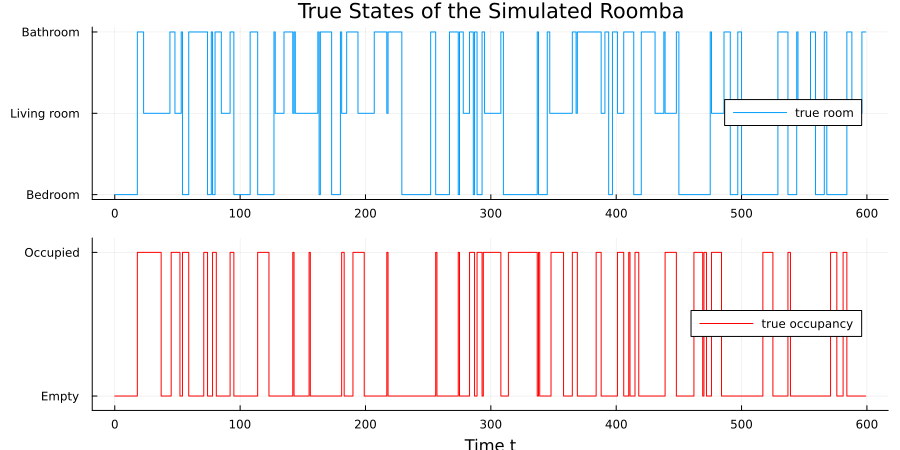

In [21]:
true_states   = [argmax(Lŝˣ[0]) for Lŝˣ in parent(Lŝˣː)]    ## joint state index (1..6) of ŝ^{*[t,0]}, t = 0, ..., T
rooms         = (true_states .+ 1) .÷ 2                      ## 1,2 → 1 (bedroom); 3,4 → 2 (livingroom); 5,6 → 3 (bathroom)
true_occupied = iseven.(true_states)                         ## states 2, 4, 6 are occupied

p_room = plot(0:T, rooms, linetype=:steppost, linestyle=:solid, leg=:right,
    label="true room", title="True States of the Simulated Roomba",
    yticks=(1:3, ["Bedroom", "Living room", "Bathroom"]))
p_occ  = plot(0:T, true_occupied, linetype=:steppost, linestyle=:solid, leg=:right,
    label="true occupancy", xlabel="Time t",
    yticks=([0, 1], ["Empty", "Occupied"]), ylims=(-0.1, 1.1), color=:red)
plot(p_room, p_occ, layout=@layout([a; b]), size=(900, 450))

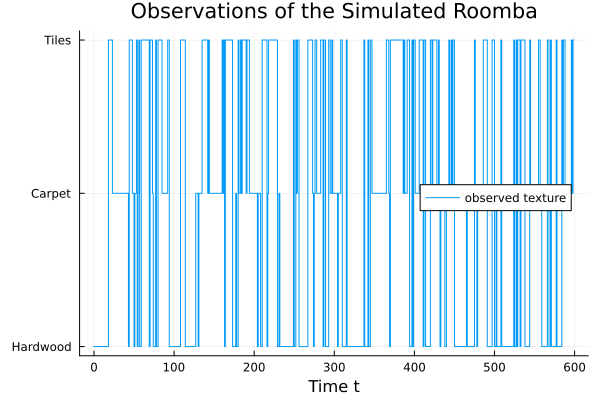

In [22]:
textures = [argmax(Lô[0]) for Lô in parent(Lôː)]    ## texture index (1, 2, 3) of ô^{[t,0]} for t = 0, ..., T
plot(title="Observations of the Simulated Roomba")
plot!(
    0:T, textures, linetype=:steppost, linestyle=:solid, leg=:right,
    label="observed texture", xlabel="Time t", yticks=(1:3, ["Hardwood", "Carpet", "Tiles"]))

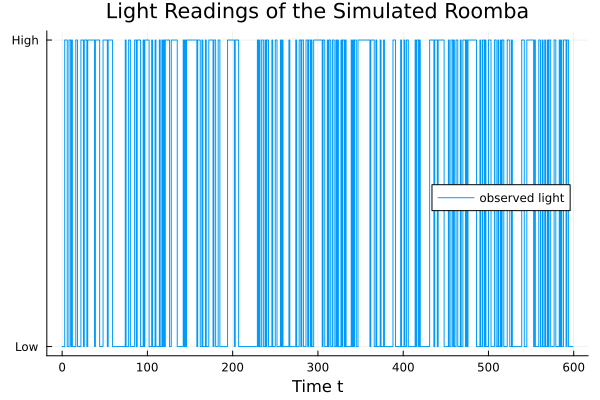

In [23]:
lights = [argmax(Lô[1]) for Lô in parent(Lôː)]    ## light index (1 = low, 2 = high) of ô^{[t,1]} for t = 0, ..., T
plot(title="Light Readings of the Simulated Roomba")
plot!(
    0:T, lights, linetype=:steppost, linestyle=:solid, leg=:right,
    label="observed light", xlabel="Time t", yticks=(1:2, ["Low", "High"]))

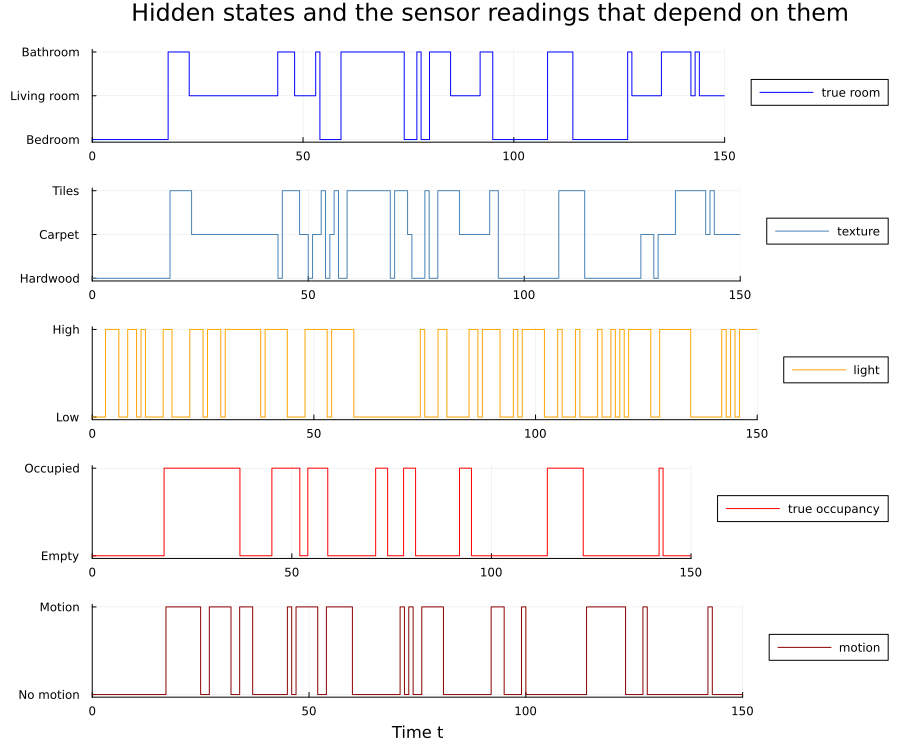

In [24]:
true_states = [argmax(Lŝˣ[0]) for Lŝˣ in parent(Lŝˣː)] ## joint state index 1..6
rooms       = (true_states .+ 1) .÷ 2               ## 1 bedroom, 2 livingroom, 3 bathroom
occupancies = iseven.(true_states) .+ 1             ## 1 empty, 2 occupied
textures    = [argmax(Lô[0]) for Lô in parent(Lôː)] ## 1 hardwood, 2 carpet, 3 tiles
lights      = [argmax(Lô[1]) for Lô in parent(Lôː)] ## 1 low, 2 high
motions     = [argmax(Lô[2]) for Lô in parent(Lôː)] ## 1 no motion, 2 motion

window = (0, 150) ## zoom in so individual ticks are visible; use (0, T) for the full run
panel(y, ticks, label, color) = plot(0:T, y, linetype=:steppost, label=label, color=color,
                                     yticks=ticks, xlims=window, legend=:outerright)

plot(
    panel(rooms,       (1:3, ["Bedroom", "Living room", "Bathroom"]), "true room",      :blue),
    panel(textures,    (1:3, ["Hardwood", "Carpet", "Tiles"]),        "texture",        :steelblue),
    panel(lights,      (1:2, ["Low", "High"]),                        "light",          :orange),
    panel(occupancies, (1:2, ["Empty", "Occupied"]),                  "true occupancy", :red),
    panel(motions,     (1:2, ["No motion", "Motion"]),                "motion",         :darkred),
    layout=(5, 1), size=(900, 750), link=:x, xlabel=["" "" "" "" "Time t"],
    plot_title="Hidden states and the sensor readings that depend on them",
)

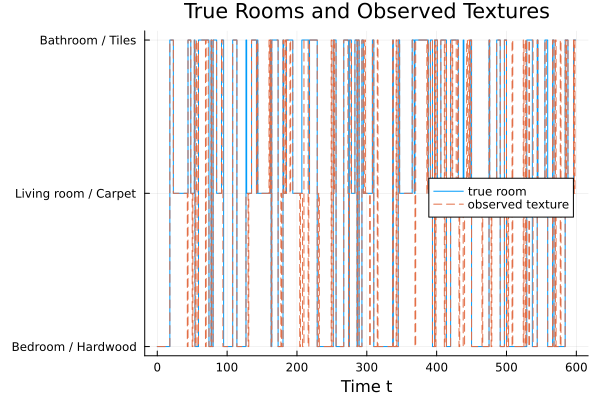

In [25]:
plot(title="True Rooms and Observed Textures")
plot!(0:T, rooms, linetype=:steppost, label="true room",
      yticks=(1:3, ["Bedroom / Hardwood", "Living room / Carpet", "Bathroom / Tiles"]))
plot!(0:T, textures, linetype=:steppost, linestyle=:dash, label="observed texture",
      xlabel="Time t", leg=:right)

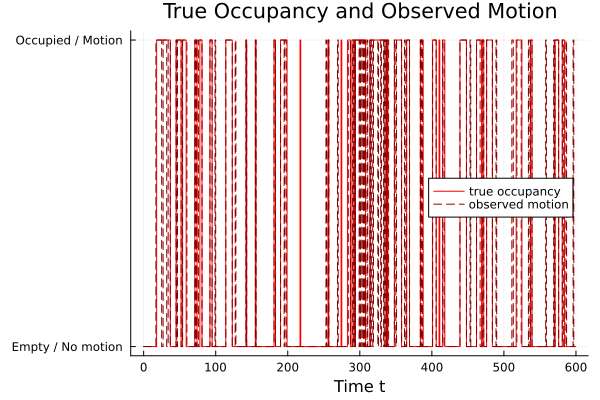

In [26]:
plot(title="True Occupancy and Observed Motion")
plot!(0:T, occupancies, linetype=:steppost, label="true occupancy", color=:red,
      yticks=(1:2, ["Empty / No motion", "Occupied / Motion"]))
plot!(0:T, motions, linetype=:steppost, linestyle=:dash, label="observed motion", color=:darkred,
      xlabel="Time t", leg=:right)

In [27]:
mistakes = count(rooms .!= textures)
println("camera mistakes: $mistakes of $(T+1) ticks ($(round(100*mistakes/(T+1), digits=1))%)")

camera mistakes: 53 of 600 ticks (8.8%)


In [28]:
occupied     = occupancies .== 2
misses       = count(occupied .& (motions .== 1))   ## person present, no motion detected
false_alarms = count(.!occupied .& (motions .== 2)) ## room empty, motion detected
println("motion sensor misses:       $misses of $(count(occupied)) occupied ticks ($(round(100*misses/count(occupied), digits=1))%)")
println("motion sensor false alarms: $false_alarms of $(count(.!occupied)) empty ticks ($(round(100*false_alarms/count(.!occupied), digits=1))%)")

motion sensor misses:       33 of 182 occupied ticks (18.1%)
motion sensor false alarms: 20 of 418 empty ticks (4.8%)


In [29]:
## The simulated fractions should come out close to 0.5, 0.85 and 0.1.
## As with the camera's mistakes, they won't be exact, because the data is a
## random sample. This uses rooms and lights from the previous plot cells,
## so run those first. A^{*[1]} has one column per joint state; room r's value
## is in column 2r-1 (empty), which equals column 2r (occupied).
for (r, room) in enumerate(["Bedroom", "Living room", "Bathroom"])
    in_room   = rooms .== r
    frac_high = mean(lights[in_room] .== 2)
    println("$room: high light $(round(frac_high, digits=2)) of $(count(in_room)) ticks (A^{*[1]}: $(LAˣ[1][2, 2r-1]))")
end

Bedroom: high light 0.48 of 235 ticks (A^{*[1]}: 0.5)
Living room: high light 0.87 of 166 ticks (A^{*[1]}: 0.85)
Bathroom: high light 0.07 of 199 ticks (A^{*[1]}: 0.1)


### 4.4 Uncertainty Model

The uncertainty in the environment is captured in the state transition matrix $\boldsymbol{B}^{\ast[0]}$ (factor 0, RoomOccupancy) and the observation generation matrices $\boldsymbol{A}^{\ast[0]}$ (modality 0, Texture), $\boldsymbol{A}^{\ast[1]}$ (modality 1, Light) and $\boldsymbol{A}^{\ast[2]}$ (modality 2, Motion). Their entries are the probabilities of the Roomba's moves and of changes in occupancy, and of the readings of the camera, the light sensor and the motion sensor. The initial state adds no uncertainty, because the Roomba always starts in the empty bedroom.

The agent's uncertainty about $\mathbf{A}^{\ast}$ itself is not part of the environment. It is captured later, in the agent's model, by priors over its own tuple of observation matrices $\mathbf{A}$. In this part, the agent has no such uncertainty about the transitions: it is given $\boldsymbol{B}^{[0]} = \boldsymbol{B}^{\ast[0]}$.

### 4.5 Agent / Generative Model
#### 4.5.1 State and Observation variables
On the agent's side, the state of the environment at time $t$ is not known: the agent represents it by a (compound) tuple of categorical random variables, one per state factor (here a single factor):

$$
\mathbf{s}^{(t)} = \big(s^{[t,0]}\big)
$$

where the *state factors* are:

- factor 0 (RoomOccupancy):
    - $s^{[t,0]} \in \{\text{bedroom-empty}, \text{bedroom-occupied}, \text{livingroom-empty}, \text{livingroom-occupied}, \text{bathroom-empty}, \text{bathroom-occupied}\}$

The agent never observes $s^{[t,0]}$ directly. What it holds instead is a *belief*, the probability vector $\boldsymbol{s}^{[t,0]} \in [0,1]^{6}$, with one probability per combination of room and occupancy. From it, the agent's belief about the room follows by adding up the empty and occupied entries of each room, and its belief that the current room is occupied by adding up the three occupied entries.

The *initial state prior* is given by

$$
P_D\big(s^{[0,0]}\big) = \mathcal{Cat}\big(s^{[0,0]};\, \boldsymbol{D}^{[0]}\big)
$$

where $\boldsymbol{D}^{[0]} \in [0,1]^{6}$ parameterizes the categorical distribution of $s^{[0,0]}$. Unlike the environment, the agent does not know that the Roomba starts in the empty bedroom, so it uses the uniform prior $\boldsymbol{D}^{[0]} = [\tfrac{1}{6}, \tfrac{1}{6}, \tfrac{1}{6}, \tfrac{1}{6}, \tfrac{1}{6}, \tfrac{1}{6}]^{\top}$.

The (compound) observation tuple received by the agent at time $t$ is the same one the environment generates:

$$
\hat{\mathbf{o}}^{(t)} = \big(\hat{\boldsymbol{o}}^{[t,0]}, \hat{\boldsymbol{o}}^{[t,1]}, \hat{\boldsymbol{o}}^{[t,2]}\big)
$$

where the *observation modalities* are:

- modality 0 (Texture):
    - $o^{[t,0]} \in \{\text{hardwood}, \text{carpet}, \text{tiles}\}$,
    - one-hot encoded as $\hat{\boldsymbol{o}}^{[t,0]} \in \big\{[1,0,0]^{\top}, [0,1,0]^{\top}, [0,0,1]^{\top}\big\}$
- modality 1 (Light):
    - $o^{[t,1]} \in \{\text{low}, \text{high}\}$,
    - one-hot encoded as $\hat{\boldsymbol{o}}^{[t,1]} \in \big\{[1,0]^{\top}, [0,1]^{\top}\big\}$
- modality 2 (Motion):
    - $o^{[t,2]} \in \{\text{no motion}, \text{motion}\}$,
    - one-hot encoded as $\hat{\boldsymbol{o}}^{[t,2]} \in \big\{[1,0]^{\top}, [0,1]^{\top}\big\}$

#### 4.5.2 Decision variables

There will be no decision variables (yet).

#### 4.5.3 Preference variables / Setpoints

There will be no preference variables (yet).

#### 4.5.4 State Transition and Observation Generation functions
The *state transition function* is given by

$$
P\big(s^{[t,0]} \mid s^{[t-1,0]}, \boldsymbol{B}^{[0]}\big) = \mathcal{Cat}\big(s^{[t,0]};\, \boldsymbol{B}^{[0]}[\bullet, s^{[t-1,0]}]\big)
$$

where $\boldsymbol{B}^{[0]}[\bullet, s^{[t-1,0]}]$, the column of $\boldsymbol{B}^{[0]}$ for the previous room, parameterizes the categorical distribution of $s^{[t,0]}$.

The *observation generation functions*, one per sensor, are given by

$$
P\big(o^{[t,m]} \mid s^{[t,0]}, \boldsymbol{A}^{[m]}\big) = \mathcal{Cat}\big(o^{[t,m]};\, \boldsymbol{A}^{[m]}[\bullet, s^{[t,0]}]\big), \qquad m = 0, 1
$$

where $\boldsymbol{A}^{[m]}[\bullet, s^{[t,0]}]$, the column of $\boldsymbol{A}^{[m]}$ for the current room, parameterizes the categorical distribution of $o^{[t,m]}$: over textures for $m = 0$, and over light intensities for $m = 1$.

An entry of $\boldsymbol{A}^{[m]}$ is the probability of a specific *observation* given a specific *state*, and each column of $\boldsymbol{A}^{[m]}$ is a categorical distribution over observations. The same holds for $\boldsymbol{B}^{[0]}$, with the next state in place of the observation. If the state were known, its column could be selected by multiplying with the one-hot encoding of that state. The agent, however, does not know the state; it only has its belief $\boldsymbol{s}^{[t,0]}$. Multiplying with the belief gives a weighted average of the columns:

- $\boldsymbol{B}^{[0]}\,\boldsymbol{s}^{[t-1,0]}$ is the agent's *predicted* belief about the next room,
- $\boldsymbol{A}^{[0]}\,\boldsymbol{s}^{[t,0]}$ and $\boldsymbol{A}^{[1]}\,\boldsymbol{s}^{[t,0]}$ are the agent's *expected* observations, of the texture and of the light intensity.

Given the room, the two sensors are independent of each other: what the camera sees does not affect what the light sensor measures. The agent therefore combines them by multiplying their likelihoods,

$$
P\big(o^{[t,0]}, o^{[t,1]} \mid s^{[t,0]}\big) = P\big(o^{[t,0]} \mid s^{[t,0]}, \boldsymbol{A}^{[0]}\big)\, P\big(o^{[t,1]} \mid s^{[t,0]}, \boldsymbol{A}^{[1]}\big)
$$

so a room that explains both readings well gains belief, while a room that explains only one of them loses some. This is how the light sensor helps where the camera is unsure.

Unlike the environment's $\boldsymbol{A}^{\ast[0]}$, $\boldsymbol{A}^{\ast[1]}$ and $\boldsymbol{B}^{\ast[0]}$, the agent's matrices $\boldsymbol{A}^{[0]}$, $\boldsymbol{A}^{[1]}$ and $\boldsymbol{B}^{[0]}$ are not known in advance: they are learned from the observations. This is why they appear as conditions in the distributions above.

#### 4.5.4 State Transition and Observation Generation functions
The *state transition function* is given by

$$
P_{B^{[0]}}\big(s^{[t,0]} \mid s^{[t-1,0]}\big) = \mathcal{Cat}\big(s^{[t,0]};\, \boldsymbol{B}^{[0]}[\bullet, s^{[t-1,0]}]\big)
$$

where $\boldsymbol{B}^{[0]}[\bullet, s^{[t-1,0]}]$, the column of $\boldsymbol{B}^{[0]}$ for the previous room and occupancy, parameterizes the categorical distribution of $s^{[t,0]}$. In this part, the agent is given $\boldsymbol{B}^{[0]} = \boldsymbol{B}^{\ast[0]}$, so $\boldsymbol{B}^{[0]}$ appears as a subscript: a known parameter, not a random variable.

The *observation generation functions*, one per sensor, are given by

$$
P\big(o^{[t,m]} \mid s^{[t,0]}, \boldsymbol{A}^{[m]}\big) = \mathcal{Cat}\big(o^{[t,m]};\, \boldsymbol{A}^{[m]}[\bullet, s^{[t,0]}]\big), \qquad m = 0, 1, 2
$$

where $\boldsymbol{A}^{[m]}[\bullet, s^{[t,0]}]$, the column of $\boldsymbol{A}^{[m]}$ for the current room and occupancy, parameterizes the categorical distribution of $o^{[t,m]}$: over textures for $m = 0$, over light intensities for $m = 1$, and over motion readings for $m = 2$.

An entry of $\boldsymbol{A}^{[m]}$ is the probability of a specific *observation* given a specific *state*, and each column of $\boldsymbol{A}^{[m]}$ is a categorical distribution over observations. The same holds for $\boldsymbol{B}^{[0]}$, with the next state in place of the observation. If the state were known, its column could be selected by multiplying with the one-hot encoding of that state. The agent, however, does not know the state; it only has its belief $\boldsymbol{s}^{[t,0]}$. Multiplying with the belief gives a weighted average of the columns:

- $\boldsymbol{B}^{[0]}\,\boldsymbol{s}^{[t-1,0]}$ is the agent's *predicted* belief about the next room and occupancy,
- $\boldsymbol{A}^{[0]}\,\boldsymbol{s}^{[t,0]}$, $\boldsymbol{A}^{[1]}\,\boldsymbol{s}^{[t,0]}$ and $\boldsymbol{A}^{[2]}\,\boldsymbol{s}^{[t,0]}$ are the agent's *expected* observations, of the texture, the light intensity and the motion reading.

Given the state, the three sensors are independent of each other: what the camera sees does not affect what the light or motion sensor measures. The agent therefore combines them by multiplying their likelihoods,

$$
P\big(o^{[t,0]}, o^{[t,1]}, o^{[t,2]} \mid s^{[t,0]}\big) = \prod_{m=0}^{2} P\big(o^{[t,m]} \mid s^{[t,0]}, \boldsymbol{A}^{[m]}\big)
$$

so a state that explains all readings well gains belief, while a state that explains only some of them loses some. The sensors divide the work: texture and light mainly tell the rooms apart, since they depend only on the room, while motion tells *empty* from *occupied*, since it depends only on occupancy. Together, they let the agent infer both parts of the joint state.

Unlike the environment's $\boldsymbol{A}^{\ast[0]}$, $\boldsymbol{A}^{\ast[1]}$ and $\boldsymbol{A}^{\ast[2]}$, the agent's observation matrices $\boldsymbol{A}^{[0]}$, $\boldsymbol{A}^{[1]}$ and $\boldsymbol{A}^{[2]}$ are not known in advance: they are learned from the observations. This is why they appear as conditions in the distributions above, while the given $\boldsymbol{B}^{[0]}$ appears as a subscript.

#### 4.5.5 Implementation of the Agent / Generative Model / Internal Model
We start by specifying a probabilistic model for the agent that describes the agent's internal beliefs about the external dynamics of the environment. The generative model is defined as follows:

$$
\begin{aligned}
&P\big(o^{[0:T,0]}, o^{[0:T,1]}, o^{[0:T,2]}, s^{[0:T,0]}, \boldsymbol{A}^{[0]}, \boldsymbol{A}^{[1]}, \boldsymbol{A}^{[2]}\big) \\[4pt]
&\quad= \underbrace{P_{\check{a}^{[0]}}\big(\boldsymbol{A}^{[0]}\big)\, P_{\check{a}^{[1]}}\big(\boldsymbol{A}^{[1]}\big)\, P_{\check{a}^{[2]}}\big(\boldsymbol{A}^{[2]}\big)}_{\text{parameter prior}}
   \,\underbrace{P_D\big(s^{[0,0]}\big)}_{\substack{\text{state}\\ \text{prior}}}
   \prod_{t=0}^{T} \prod_{m=0}^{2} \underbrace{P_{A^{[m]}}\big(o^{[t,m]} \mid s^{[t,0]}\big)}_{\substack{\text{observation-generation}\\ \text{model}}}
   \prod_{t=1}^{T} \underbrace{P_{B^{[0]}}\big(s^{[t,0]} \mid s^{[t-1,0]}\big)}_{\substack{\text{state-transition}\\ \text{model}}} \\[6pt]
&\quad= P_{\check{a}^{[0]}}\big(\boldsymbol{A}^{[0]}\big)\, P_{\check{a}^{[1]}}\big(\boldsymbol{A}^{[1]}\big)\, P_{\check{a}^{[2]}}\big(\boldsymbol{A}^{[2]}\big)
   \, P_D\big(s^{[0,0]}\big)
   \prod_{t=0}^{T} \prod_{m=0}^{2} P\big(o^{[t,m]} \mid s^{[t,0]}, \boldsymbol{A}^{[m]}\big)
   \prod_{t=1}^{T} P_{B^{[0]}}\big(s^{[t,0]} \mid s^{[t-1,0]}\big)
\end{aligned}
$$

where $\check{\boldsymbol{a}}^{[0]}$, $\check{\boldsymbol{a}}^{[1]}$ and $\check{\boldsymbol{a}}^{[2]}$ are the concentration parameters of the `DirichletCollection` priors on $\boldsymbol{A}^{[0]}$, $\boldsymbol{A}^{[1]}$ and $\boldsymbol{A}^{[2]}$, $\boldsymbol{D}^{[0]}$ is the agent's uniform initial state prior from 4.5.1, and $\boldsymbol{B}^{[0]} = \boldsymbol{B}^{\ast[0]}$ is the transition matrix the agent is given. The three observation matrices get different priors:

- $\check{\boldsymbol{a}}^{[0]}$ expresses trust in the camera,
- $\check{\boldsymbol{a}}^{[1]}$ is flat, so the agent learns the light sensor's behavior from the data alone, and
- $\check{\boldsymbol{a}}^{[2]}$ expresses the basic meaning of the motion sensor: motion suggests an occupied room. Without this, the agent could not tell which of its states mean *occupied*: with a flat prior, the labels *empty* and *occupied* would be interchangeable.

The two lines say the same thing in two notations. In the first, the subscripts mark which matrix parameterizes each distribution. In the second, $\boldsymbol{A}^{[0]}$, $\boldsymbol{A}^{[1]}$ and $\boldsymbol{A}^{[2]}$ appear as explicit conditions: because the agent *learns* them, they are random variables with their own priors, not fixed numbers. $\boldsymbol{D}^{[0]}$ and $\boldsymbol{B}^{[0]}$ are not learned, so they remain subscripts in both lines.

The product over $m$ is where the three sensors are combined: at each time step, all three observations depend on the same state $s^{[t,0]}$, and given that state, they are independent.

Now it is time to build our model. As mentioned earlier, we will use categorical distributions for the states and observations. To learn the agent's observation matrices $\boldsymbol{A}^{[0]}$, $\boldsymbol{A}^{[1]}$ and $\boldsymbol{A}^{[2]}$, we give them `DirichletCollection` priors: a Dirichlet distribution over each column, with concentration parameters $\check{\boldsymbol{a}}^{[0]}$, $\check{\boldsymbol{a}}^{[1]}$ and $\check{\boldsymbol{a}}^{[2]}$:

$$
P_{\check{a}^{[m]}}\big(\boldsymbol{A}^{[m]}\big) = \mathcal{DirColl}\big(\boldsymbol{A}^{[m]};\, \check{\boldsymbol{a}}^{[m]}\big), \qquad m = 0, 1, 2
$$

The concentration parameters act as pseudo-counts: imagined observations the agent starts out with, before it has seen any data. Each matrix has one column per joint state, so each prior has six columns as well.

The transition matrix is not learned in this part: the agent is given $\boldsymbol{B}^{[0]} = \boldsymbol{B}^{\ast[0]}$, so it knows how the Roomba moves and how occupancy changes. This keeps the focus on inferring occupancy. If inference goes poorly, we then know it is not because the agent is still learning the dynamics.

As for the camera, we have good reason to trust it. To represent this, we put large values on the entries of $\check{\boldsymbol{a}}^{[0]}$ that match each room with its own texture, i.e. many pseudo-counts for correct readings, in both the empty and the occupied column of each room. However, we also acknowledge that the camera is not infallible, so we put small positive values on the other entries, which allow for the occasional misreading.

For the light sensor, we deliberately give the agent no prior knowledge: we fill $\check{\boldsymbol{a}}^{[1]}$ with ones, so the agent does not know in advance which rooms tend to be bright. It has to learn $\boldsymbol{A}^{[1]}$ from the data, anchored by the camera, which tells it fairly reliably which room it is in.

For the motion sensor, the agent needs some prior knowledge: that motion suggests an occupied room. We therefore put large values on *motion* in the occupied columns of $\check{\boldsymbol{a}}^{[2]}$ and on *no motion* in the empty columns, with small values elsewhere. Without this, the agent could not tell which of its states mean *occupied*: with a flat prior, the labels *empty* and *occupied* would be interchangeable. The prior only fixes this meaning; the agent still learns how reliable the sensor is from the data. Comparing the learned $\boldsymbol{A}^{[1]}$ and $\boldsymbol{A}^{[2]}$ with the true $\boldsymbol{A}^{\ast[1]}$ and $\boldsymbol{A}^{\ast[2]}$ afterwards shows how well this works.

Since we will use variational inference, we also have to specify inference constraints. We will use a structured variational approximation to the true posterior distribution, in which the variational posterior over the trajectory of states is decoupled from the posteriors over the three observation matrices:

$$
Q\big(s^{[0:T,0]}, \boldsymbol{A}^{[0]}, \boldsymbol{A}^{[1]}, \boldsymbol{A}^{[2]}\big) = Q\big(s^{[0:T,0]}\big)\, Q\big(\boldsymbol{A}^{[0]}\big)\, Q\big(\boldsymbol{A}^{[1]}\big)\, Q\big(\boldsymbol{A}^{[2]}\big)
$$

The states keep their dependencies on each other over time, which is what makes the approximation *structured* rather than fully factorized. Decoupling the states from the matrices is what makes inference tractable. Let's build the model!

In [30]:
@model function hidden_markov_model(o⁰ː, o¹ː, o²ː, _B, T)
    _A⁰ ~ DirichletCollection(repeat([10.0  1.0  1.0;
                                       1.0 10.0  1.0;
                                       1.0  1.0 10.0], inner=(1, 2))) ## P_{ǎ^{[0]}}(A^{[0]}): Texture, trusted camera (3×6)
    _A¹ ~ DirichletCollection(ones(2, 6))                             ## P_{ǎ^{[1]}}(A^{[1]}): Light, learned from scratch (2×6)
    _A² ~ DirichletCollection(repeat([9.0 1.0;
                                      1.0 9.0], outer=(1, 3)))        ## P_{ǎ^{[2]}}(A^{[2]}): Motion, motion suggests occupied (2×6)

    sː[1]  ~ Categorical(fill(1.0/6.0, 6))  ## t = 0: P_D(s^{[0,0]}), uniform over 6 joint states
    o⁰ː[1] ~ DiscreteTransition(sː[1], _A⁰) ## t = 0: P(o^{[0,0]} | s^{[0,0]}, A^{[0]})
    o¹ː[1] ~ DiscreteTransition(sː[1], _A¹) ## t = 0: P(o^{[0,1]} | s^{[0,0]}, A^{[1]})
    o²ː[1] ~ DiscreteTransition(sː[1], _A²) ## t = 0: P(o^{[0,2]} | s^{[0,0]}, A^{[2]})
    for t in 1:T
        sː[t+1]  ~ DiscreteTransition(sː[t], _B)     ## P_{B^{[0]}}(s^{[t,0]} | s^{[t-1,0]}), B given
        o⁰ː[t+1] ~ DiscreteTransition(sː[t+1], _A⁰)  ## P(o^{[t,0]} | s^{[t,0]}, A^{[0]})
        o¹ː[t+1] ~ DiscreteTransition(sː[t+1], _A¹)  ## P(o^{[t,1]} | s^{[t,0]}, A^{[1]})
        o²ː[t+1] ~ DiscreteTransition(sː[t+1], _A²)  ## P(o^{[t,2]} | s^{[t,0]}, A^{[2]})
    end
end

@constraints function hidden_markov_model_constraints()
    q(sː, _A⁰, _A¹, _A²) = q(sː)q(_A⁰)q(_A¹)q(_A²)
end

hidden_markov_model_constraints (generic function with 1 method)

**Notes on the model code**

*Names: the model mirrors the agent's math.*

- `sː`, `o⁰ː`, `o¹ː` and `o²ː` have no hats and no prefix. Inside the model, these are the agent's *random variables*, $s^{[0:T,0]}$, $o^{[0:T,0]}$ (Texture), $o^{[0:T,1]}$ (Light) and $o^{[0:T,2]}$ (Motion), the unbold symbols on the left-hand side of the generative model. The data fills in the observations, but in the model, `o⁰ː`, `o¹ː` and `o²ː` are still the variables being observed.
- `_A⁰`, `_A¹`, `_A²` and `_B` are single italic-bold matrices, $\boldsymbol{A}^{[0]}$, $\boldsymbol{A}^{[1]}$, $\boldsymbol{A}^{[2]}$ and $\boldsymbol{B}^{[0]}$. A model has no tuples, and `tuple0` indexing would not work inside `@model` anyway, so the modality index is part of the names, as a superscript digit. With a single state factor, the index of `_B` is left implicit.
- `_B` is a model argument rather than a random variable: the agent is given $\boldsymbol{B}^{[0]} = \boldsymbol{B}^{\ast[0]}$, so it has no prior and does not appear in the constraints.
- The comments map each line of the model to the corresponding factor of the generative model.

*Structure: three observations per time step, starting at $t = 0$.*

The uniform prior over the six joint states applies to $s^{[0,0]}$ itself, the state is also observed at $t = 0$, and there are $T + 1 = 600$ time steps, matching the generative model and the simulated data. In the code:

- The prior goes directly on `sː[1]` (that is, $t = 0$), and the first observations of all three sensors are attached to it.
- At every time step, all three observations are attached to the same state `sː[t+1]`. This is the product over $m$ in the generative model: given the state, the three sensors are independent.
- The loop variable `t` is the math's $t$. The storage index is `t+1` only because RxInfer's vectors start at 1, so `sː[t+1]` holds $s^{[t,0]}$.
- The constraints factorize as `q(sː)q(_A⁰)q(_A¹)q(_A²)`, i.e. $Q\big(s^{[0:T,0]}\big)\, Q\big(\boldsymbol{A}^{[0]}\big)\, Q\big(\boldsymbol{A}^{[1]}\big)\, Q\big(\boldsymbol{A}^{[2]}\big)$.

The data is passed to inference under the model's names for the observations, as one 1-based vector per sensor: `data = (o⁰ː = Lô⁰ː_data, o¹ː = Lô¹ː_data, o²ː = Lô²ː_data)`. The known transition matrix is passed as a model argument: `hidden_markov_model(_B = LBˣ[0], T = T)`.

The model uses RxInfer's `DiscreteTransition` node, which older RxInfer versions called `Transition`, and `DirichletCollection` priors, which older versions called `MatrixDirichlet`.

Next, we define the agent and the time-stepping procedure.

In [31]:
function create_agent(; Lô⁰ː_data, Lô¹ː_data, Lô²ː_data, _B)
    @assert length(Lô⁰ː_data) == length(Lô¹ː_data) == length(Lô²ː_data) "all sensors must cover the same time steps"
    T = length(Lô⁰ː_data) - 1    ## observations at t = 0, ..., T

    compute = () -> begin
        imarginals = @initialization begin
            q(_A⁰) = DirichletCollection(ones(3, 6)) ## Texture: 3 textures   × 6 joint states
            q(_A¹) = DirichletCollection(ones(2, 6)) ## Light:   2 levels     × 6 joint states
            q(_A²) = DirichletCollection(ones(2, 6)) ## Motion:  2 readings   × 6 joint states
            q(sː)  = vague(Categorical, 6)
        end
        infer(
            model          = hidden_markov_model(_B=_B, T=T),
            data           = (o⁰ː = Lô⁰ː_data, o¹ː = Lô¹ː_data, o²ː = Lô²ː_data),
            constraints    = hidden_markov_model_constraints(),
            initialization = imarginals,
            returnvars     = (_A⁰ = KeepLast(), _A¹ = KeepLast(), _A² = KeepLast(), sː = KeepLast()),
            iterations     = 20,
            free_energy    = true,
        )
    end

    return compute
end

create_agent (generic function with 1 method)

### 4.6 Agent Evaluation
Now it's time to perform inference and find out where the Roomba went in our absence, and whether it had company. Did it remember to clean the bathroom, and did it disturb anyone while doing so?

We'll be using variational inference, which improves its estimates over a number of iterations (here 20). It therefore needs initial marginals as a starting point. For the state, RxInfer's `vague` function provides an uninformative guess; for the observation matrices, we start from flat Dirichlet distributions. If you have better ideas, you can try a different initial guess and see what happens.

Inference gives us four things: the posterior over room and occupancy at every time step, $Q\big(s^{[0:T,0]}\big)$, and the posteriors over the agent's three observation matrices, $Q\big(\boldsymbol{A}^{[0]}\big)$ (Texture), $Q\big(\boldsymbol{A}^{[1]}\big)$ (Light) and $Q\big(\boldsymbol{A}^{[2]}\big)$ (Motion). The transition matrix $\boldsymbol{B}^{[0]}$ is given, so it has no posterior. From the posterior over the six joint states, we obtain the agent's belief about the room and about occupancy by adding up the right entries. Since we're only interested in the final estimates, we keep only the result of the last iteration (`KeepLast()`), which still contains the posterior for every time step. We also track the free energy, which should decrease over the iterations as the estimates improve. Let's start the inference process!

#### 4.6.1 Evaluate with simulated data

##### 4.6.1.1 Naive approach {N/A}

##### 4.6.1.2 Active inference approach

In [32]:
### Simulation parameters
## Time steps t = 0, ..., T (600 ticks)
T = 599

## Initial state: the Roomba starts in the empty bedroom
## positions: 1 bedroom-empty, 2 bedroom-occupied, 3 livingroom-empty,
##            4 livingroom-occupied, 5 bathroom-empty, 6 bathroom-occupied
Lŝˣ₀ = tuple0([1.0, 0.0, 0.0, 0.0, 0.0, 0.0])    ## ŝ^{*(0)} = (ŝ^{*[0,0]})

1-element OffsetArray(::Vector{Vector{Float64}}, 0:0) with eltype Vector{Float64} with indices 0:0:
 [1.0, 0.0, 0.0, 0.0, 0.0, 0.0]

In [26]:
### OVERRIDES

Let's take a look at our results. If we're successful, we should have a good idea about how often the Roomba's camera misreads the floor (a good posterior over $\boldsymbol{A}^{[0]}$), about how bright each room tends to be (a good posterior over $\boldsymbol{A}^{[1]}$), and about how reliably the motion sensor detects a person (a good posterior over $\boldsymbol{A}^{[2]}$). Since we simulated the data ourselves, we can check this directly: the agent's estimates should come close to the true $\boldsymbol{A}^{\ast[0]}$, $\boldsymbol{A}^{\ast[1]}$ and $\boldsymbol{A}^{\ast[2]}$. The layout of the apartment is not learned this time: the agent was given $\boldsymbol{B}^{[0]}$. The light sensor is the most interesting case for learning, because the agent started without any prior knowledge about it. For the motion sensor, the prior only told the agent that motion suggests an occupied room; how often the sensor misses a person or raises a false alarm, it has to learn from the data. Let's see if it worked.

In [33]:
## Environment: generate t = 0, ..., T
(execute_ai, observe_ai, state_ai) = create_envir(; LAˣ=LAˣ, LBˣ=LBˣ, Lŝˣ₀=Lŝˣ₀)
Lŝˣː = offset0(Vector{Any}(undef, T+1))    ## ŝ^{*(0:T)}: true states (room and occupancy)
Lôː  = offset0(Vector{Any}(undef, T+1))    ## ô^{(0:T)}: observations, each a tuple (Texture, Light, Motion)
for t = 0:T
    t > 0 && execute_ai()    ## move and observe (t = 0 is already set up)
    Lŝˣː[t] = state_ai()
    Lôː[t]  = observe_ai()
end

## Agent: infer room and occupancy, and learn A^{[0]}, A^{[1]}, A^{[2]} from all observations at once (B^{[0]} given)
Lô⁰ː_data  = [Lô[0] for Lô in parent(Lôː)]    ## Texture, 1-based copy for RxInfer
Lô¹ː_data  = [Lô[1] for Lô in parent(Lôː)]    ## Light,   1-based copy for RxInfer
Lô²ː_data  = [Lô[2] for Lô in parent(Lôː)]    ## Motion,  1-based copy for RxInfer
compute_ai = create_agent(; Lô⁰ː_data=Lô⁰ː_data, Lô¹ː_data=Lô¹ː_data, Lô²ː_data=Lô²ː_data, _B=LBˣ[0])
result     = compute_ai()

Inference results:
  Posteriors       | available for (_A⁰, sː, _A², _A¹)
  Free Energy:     | Real[1519.49, 1395.52, 1172.21, 1064.99, 1029.77, 1023.61, 1022.76, 1022.59, 1022.53, 1022.5, 1022.49, 1022.48, 1022.48, 1022.47, 1022.47, 1022.47, 1022.47, 1022.47, 1022.47, 1022.47]


In [34]:
[Lŝˣ[0] for Lŝˣ in Lŝˣː] ## ŝ^{*[t,0]} for t = 0, ..., T: the true RoomOccupancy factor (one-hot over 6 joint states)

600-element OffsetArray(::Vector{Vector{Float64}}, 0:599) with eltype Vector{Float64} with indices 0:599:
 [1.0, 0.0, 0.0, 0.0, 0.0, 0.0]
 [1.0, 0.0, 0.0, 0.0, 0.0, 0.0]
 [1.0, 0.0, 0.0, 0.0, 0.0, 0.0]
 [1.0, 0.0, 0.0, 0.0, 0.0, 0.0]
 [1.0, 0.0, 0.0, 0.0, 0.0, 0.0]
 [1.0, 0.0, 0.0, 0.0, 0.0, 0.0]
 [1.0, 0.0, 0.0, 0.0, 0.0, 0.0]
 [1.0, 0.0, 0.0, 0.0, 0.0, 0.0]
 [1.0, 0.0, 0.0, 0.0, 0.0, 0.0]
 [1.0, 0.0, 0.0, 0.0, 0.0, 0.0]
 ⋮
 [0.0, 0.0, 1.0, 0.0, 0.0, 0.0]
 [0.0, 0.0, 1.0, 0.0, 0.0, 0.0]
 [0.0, 0.0, 1.0, 0.0, 0.0, 0.0]
 [0.0, 0.0, 1.0, 0.0, 0.0, 0.0]
 [0.0, 0.0, 1.0, 0.0, 0.0, 0.0]
 [0.0, 0.0, 0.0, 0.0, 1.0, 0.0]
 [0.0, 0.0, 0.0, 0.0, 1.0, 0.0]
 [0.0, 0.0, 0.0, 0.0, 1.0, 0.0]
 [0.0, 0.0, 0.0, 0.0, 1.0, 0.0]

In [35]:
[state_labels[argmax(Lŝˣ[0])] for Lŝˣ in Lŝˣː] ## true state at t = 0, ..., T, by name

600-element OffsetArray(::Vector{String}, 0:599) with eltype String with indices 0:599:
 "bedroom-empty"
 "bedroom-empty"
 "bedroom-empty"
 "bedroom-empty"
 "bedroom-empty"
 "bedroom-empty"
 "bedroom-empty"
 "bedroom-empty"
 "bedroom-empty"
 "bedroom-empty"
 ⋮
 "livingroom-empty"
 "livingroom-empty"
 "livingroom-empty"
 "livingroom-empty"
 "livingroom-empty"
 "bathroom-empty"
 "bathroom-empty"
 "bathroom-empty"
 "bathroom-empty"

In [36]:
[Lô[0] for Lô in Lôː] ## ô^{[t,0]} for t = 0, ..., T: the received Texture observations

600-element OffsetArray(::Vector{Vector{Float64}}, 0:599) with eltype Vector{Float64} with indices 0:599:
 [1.0, 0.0, 0.0]
 [1.0, 0.0, 0.0]
 [1.0, 0.0, 0.0]
 [1.0, 0.0, 0.0]
 [1.0, 0.0, 0.0]
 [1.0, 0.0, 0.0]
 [1.0, 0.0, 0.0]
 [1.0, 0.0, 0.0]
 [1.0, 0.0, 0.0]
 [1.0, 0.0, 0.0]
 ⋮
 [0.0, 1.0, 0.0]
 [0.0, 1.0, 0.0]
 [0.0, 1.0, 0.0]
 [0.0, 1.0, 0.0]
 [0.0, 1.0, 0.0]
 [0.0, 0.0, 1.0]
 [0.0, 1.0, 0.0]
 [0.0, 0.0, 1.0]
 [0.0, 0.0, 1.0]

In [37]:
[Lô[1] for Lô in Lôː] ## ô^{[t,1]} for t = 0, ..., T: the received Light observations

600-element OffsetArray(::Vector{Vector{Float64}}, 0:599) with eltype Vector{Float64} with indices 0:599:
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [0.0, 1.0]
 [0.0, 1.0]
 [0.0, 1.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [0.0, 1.0]
 [0.0, 1.0]
 ⋮
 [1.0, 0.0]
 [0.0, 1.0]
 [0.0, 1.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]

In [38]:
[Lô[2] for Lô in Lôː] ## ô^{[t,2]} for t = 0, ..., T: the received Motion observations

600-element OffsetArray(::Vector{Vector{Float64}}, 0:599) with eltype Vector{Float64} with indices 0:599:
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 ⋮
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [0.0, 1.0]
 [1.0, 0.0]
 [1.0, 0.0]
 [1.0, 0.0]

In [39]:
result.posteriors

Dict{Symbol, Any} with 4 entries:
  :_A⁰ => DirichletCollection{Float64, 2, Matrix{Float64}}(…
  :sː  => Categorical{Float64, Vector{Float64}}[Categorical{Float64, Vector{Flo…
  :_A² => DirichletCollection{Float64, 2, Matrix{Float64}}(…
  :_A¹ => DirichletCollection{Float64, 2, Matrix{Float64}}(…

In [40]:
println("Transition matrix B^{[0]} (RoomOccupancy), given to the agent:")
LBˣ[0]    ## B^{[0]} = B^{*[0]}, not learned in this part

Transition matrix B^{[0]} (RoomOccupancy), given to the agent:


6×6 Matrix{Float64}:
 0.855  0.09  0.0    0.0   0.07  0.07
 0.045  0.81  0.0    0.0   0.03  0.03
 0.0    0.0   0.855  0.09  0.05  0.05
 0.0    0.0   0.045  0.81  0.05  0.05
 0.09   0.09  0.09   0.09  0.76  0.08
 0.01   0.01  0.01   0.01  0.04  0.72

This compares well with:
```
LBˣ[0] = [
0.9  0.0  0.1;
0.0  0.9  0.1;
0.1  0.1  0.8]
```



In [41]:
println("Posterior mean of A^{[0]} (Texture likelihood):")
_Ā⁰ = mean(result.posteriors[:_A⁰]) ## Ā^{[0]} = E_Q[A^{[0]}], the agent's estimate of A^{*[0]}

Posterior mean of A^{[0]} (Texture likelihood):


3×6 Matrix{Float64}:
 0.91163    0.913019   0.0594208  0.0729868  0.0481594  0.0519372
 0.0249474  0.0332082  0.915264   0.866835   0.0641686  0.164049
 0.0634231  0.0537732  0.0253154  0.0601777  0.887672   0.784014

<!-- This compares well with:
```
LAˣ[0] = [
0.9  0.05 0.05;
0.05 0.9  0.05;
0.05 0.05 0.9] 
``` -->

This compares well with:
```
LAˣ[0] = [
0.9  0.9  0.05 0.05 0.05 0.05;
0.05 0.05 0.9  0.9  0.05 0.05;
0.05 0.05 0.05 0.05 0.9  0.9 ]
```

In [42]:
println("Posterior mean of A^{[1]} (Light likelihood):")
_Ā¹ = mean(result.posteriors[:_A¹])    ## Ā^{[1]} = E_Q[A^{[1]}], the agent's estimate of A^{*[1]} (2×6)

Posterior mean of A^{[1]} (Light likelihood):


2×6 Matrix{Float64}:
 0.526824  0.518316  0.150915  0.105986  0.946619   0.857295
 0.473176  0.481684  0.849085  0.894014  0.0533808  0.142705

<!-- This compares well with:
```
LAˣ[1] = [
0.5  0.15 0.9;
0.5  0.85 0.1]
``` -->

This compares well with:
```
LAˣ[1] = [
0.5  0.5  0.15 0.15 0.9  0.9;
0.5  0.5  0.85 0.85 0.1  0.1]
```

In [43]:
println("Posterior mean of A^{[2]} (Motion likelihood):")
_Ā² = mean(result.posteriors[:_A²])    ## Ā^{[2]} = E_Q[A^{[2]}], the agent's estimate of A^{*[2]} (2×6)

Posterior mean of A^{[2]} (Motion likelihood):


2×6 Matrix{Float64}:
 0.947308  0.167289  0.971757   0.157233  0.920476   0.0635338
 0.052692  0.832711  0.0282432  0.842767  0.0795237  0.936466

This compares well with:
```
LAˣ[2] = [
0.95 0.2  0.95 0.2  0.95 0.2;
0.05 0.8  0.05 0.8  0.05 0.8]
```

Finally, we can check whether we were successful in keeping tabs on our Roomba's whereabouts, and on whether it had company. From the posterior $Q\big(s^{[t,0]}\big)$ over the six joint states, we derive the agent's most probable room at each time step and its probability that the room is occupied. We compare both with the true state $\hat{\boldsymbol{s}}^{\ast[t,0]}$: the room the Roomba was actually in, and whether that room was actually occupied. We expect the room to be tracked about as well as in Part 2, since the camera still does most of that work. For occupancy, the motion sensor is the main source of evidence, but the agent can do better than the motion sensor alone: occupancy usually persists while the Roomba stays in a room, so a single missed person or false alarm can be overruled by the readings around it. We can also check whether the inference has converged by looking at the free energy: it should decrease over the iterations and then level off.

camera misread the floor at 53 of 600 ticks; agent still inferred the right room at 88.7% of those
motion sensor was wrong at 53 of 600 ticks; agent still inferred the right occupancy at 49.1% of those


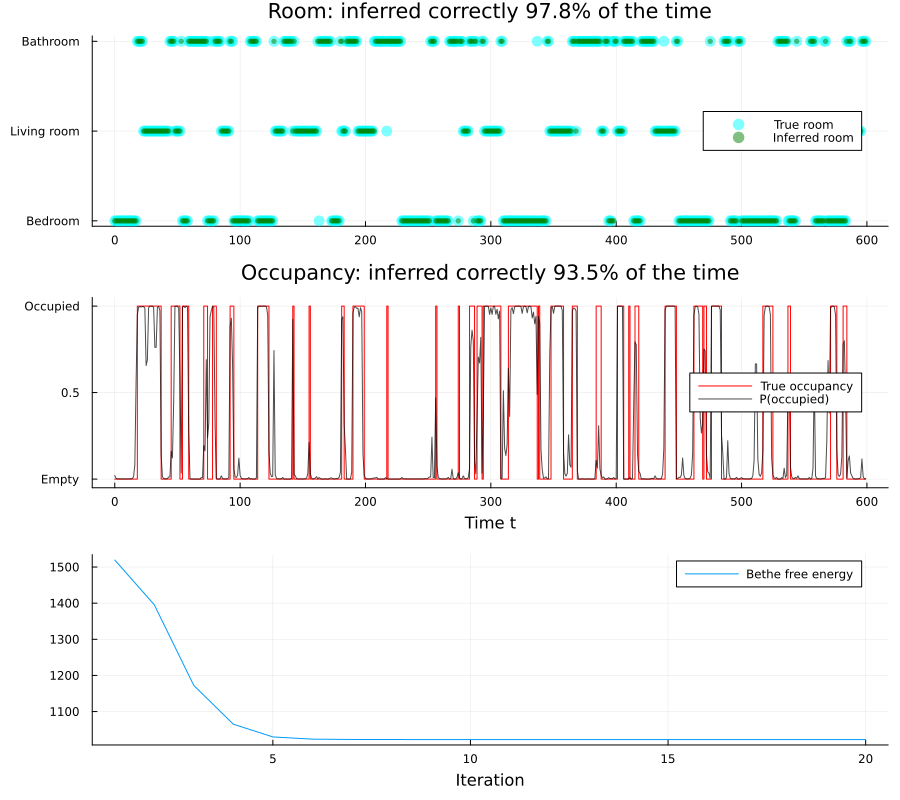

In [44]:
Lqsː = offset0(result.posteriors[:sː])    ## Q(s^{[t,0]}) over 6 joint states, t = 0, ..., T (0-based)

## from joint states to room and occupancy (state order: room by room, empty before occupied)
room_of(p) = [p[1]+p[2], p[3]+p[4], p[5]+p[6]] ## marginal over rooms
occ_of(p)  = p[2] + p[4] + p[6]                ## probability that the room is occupied

true_states    = [argmax(Lŝˣ[0]) for Lŝˣ in parent(Lŝˣː)] ## true joint state index 1..6
rooms          = (true_states .+ 1) .÷ 2                  ## true room: 1 bedroom, 2 livingroom, 3 bathroom
true_occupied  = iseven.(true_states)                     ## true occupancy

q_states       = [ReactiveMP.probvec(q) for q in parent(Lqsː)]
inferred_rooms = [argmax(room_of(p)) for p in q_states] ## most probable room under Q(s^{[t,0]})
p_occupied     = [occ_of(p) for p in q_states]          ## agent's probability that the room is occupied
inferred_occ   = p_occupied .> 0.5

accuracy_room = mean(inferred_rooms .== rooms)
accuracy_occ  = mean(inferred_occ .== true_occupied)

## where the camera misread the floor, did the agent still get the room right?
textures            = [argmax(Lô[0]) for Lô in parent(Lôː)]
camera_wrong        = textures .!= rooms
accuracy_cam_wrong  = mean(inferred_rooms[camera_wrong] .== rooms[camera_wrong])
println("camera misread the floor at $(count(camera_wrong)) of $(T+1) ticks; ",
        "agent still inferred the right room at $(round(100*accuracy_cam_wrong, digits=1))% of those")

## where the motion sensor was wrong, did the agent still get occupancy right?
motion_detected     = [argmax(Lô[2]) for Lô in parent(Lôː)] .== 2
motion_wrong        = motion_detected .!= true_occupied
accuracy_mot_wrong  = mean(inferred_occ[motion_wrong] .== true_occupied[motion_wrong])
println("motion sensor was wrong at $(count(motion_wrong)) of $(T+1) ticks; ",
        "agent still inferred the right occupancy at $(round(100*accuracy_mot_wrong, digits=1))% of those")

p1 = scatter(0:T, rooms,
    title="Room: inferred correctly $(round(100*accuracy_room, digits=1))% of the time",
    label="True room", legend=:right,
    yticks=(1:3, ["Bedroom", "Living room", "Bathroom"]),
    markercolor=:cyan, markersize=6, markerstrokewidth=0, alpha=.5)
scatter!(p1, 0:T, inferred_rooms,
    label="Inferred room", markercolor=:green, markersize=3, markerstrokewidth=0, alpha=.5)

p2 = plot(0:T, true_occupied, linetype=:steppost, color=:red, label="True occupancy",
    title="Occupancy: inferred correctly $(round(100*accuracy_occ, digits=1))% of the time",
    yticks=([0, 0.5, 1], ["Empty", "0.5", "Occupied"]), ylims=(-0.05, 1.05), legend=:right)
plot!(p2, 0:T, p_occupied, color=:black, alpha=0.7, label="P(occupied)", xlabel="Time t")

p3 = plot(result.free_energy, label="Bethe free energy", xlabel="Iteration")

plot(p1, p2, p3, layout=@layout([a; b; c]), size=(900, 800))

### 4.7 Conclusion and outlook

In this part, the agent learned to infer not only *where* the Roomba is, but also *whether it has company*. Three choices made this possible with little extra machinery:

- **Room and occupancy share one state factor.** With six joint states, the model expresses directly that occupancy persists while the Roomba stays in a room, and is drawn fresh when it enters another one. The agent's beliefs about the room and about occupancy follow from its joint belief by adding up the right entries.
- **Each sensor does its own job.** Texture and light depend only on the room, motion depends only on occupancy. Combined, they let the agent infer both parts of the joint state.
- **The motion prior fixes the meaning of *occupied*.** Without it, the agent could not tell which of its states mean *occupied* and which mean *empty*. The prior only fixes this meaning; how reliable the sensor is, the agent learns from the data.

The results in 4.6 show how well this works. Room tracking is about as good as in Part 2, since the camera still does most of that work. For occupancy, the agent does more than repeat the motion sensor: because occupancy usually persists, a single missed person or false alarm can be overruled by the readings around it, which is visible wherever the agent's probability of *occupied* stays steady while the motion readings flicker.

To keep the focus on inferring occupancy, the agent was given the transition matrix $\boldsymbol{B}^{[0]}$. A natural extension is to let it learn $\boldsymbol{B}^{[0]}$ as well, as it did with the room transitions in Part 2.

**Next: from inference to control.** So far, the Roomba moves at random and the agent only watches. In the next part, the Roomba gets to choose where to go, and the agent gets *preferences*: it should prefer to clean where it does not disturb anyone. In active inference, such preferences are expressed over observations, so this becomes a preference for *no motion*, encoded in a preference vector for the motion sensor. The ingredients from this part carry over directly:

- the joint state and the motion sensor, which let the agent tell occupied from empty rooms,
- the transition matrix, which will get one version per action, describing where each move is likely to take the Roomba, and
- the functions `act()`, `future()` and `slide()` in `create_agent()`, still marked *not yet*, which will turn the agent's inference into decisions.

The Roomba will then no longer just be tracked: it will choose to avoid company.